**1. Установка необходимых библиотек и импорт.**

In [20]:
import sys

print(sys.executable)
print(sys.version)

%pip install --upgrade pip
%pip install -q pandas numpy matplotlib seaborn scikit-learn xgboost lightgbm catboost requests optuna phik mlflow

''' Эксперименты с great_expectations сделаны в рамках 
    курса "Интеграция ИИ в разработку", командой решили один кейс 
    по 2 дисциплинам делать, т.к. рассмотрение идет с разных сторон 
    и может получить более углубленный результат '''

%pip install "setuptools<81" --quiet
%pip install "great_expectations>=0.18.0,<1.0.0" --quiet

c:\python313\python.exe
3.13.7 (tags/v3.13.7:bcee1c3, Aug 14 2025, 14:15:11) [MSC v.1944 64 bit (AMD64)]
Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [21]:
import re
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold, train_test_split
from sklearn.pipeline import FeatureUnion, Pipeline

warnings.filterwarnings("ignore")

%matplotlib inline
# Данные остаются в Datasets; все результаты экспериментов — в outputs.
from pathlib import Path
import sys

DATASET_DIR = next(
    (candidate.resolve()
     for base in (Path.cwd(), *Path.cwd().parents)
     for candidate in (base, base / "Datasets")
     if (candidate / "df.csv").is_file()),
    None,
)
if DATASET_DIR is None:
    raise FileNotFoundError("Не найден Datasets/df.csv: запускайте ноутбук внутри репозитория.")
SCRIPTS_DIR = DATASET_DIR / "scripts"
if str(SCRIPTS_DIR) not in sys.path:
    sys.path.insert(0, str(SCRIPTS_DIR))
from dataset_paths import DATASET_DIR, NOTEBOOK_DIR, OUTPUT_DIR, EDA_OUTPUT_DIR

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Датасет:", DATASET_DIR / "df.csv")
print("Артефакты:", OUTPUT_DIR)


Датасет: D:\Pudov\УРФУ\03.Учеба\3. Семестр\SpamClickbaitClassification\Datasets\df.csv
Артефакты: D:\Pudov\УРФУ\03.Учеба\3. Семестр\SpamClickbaitClassification\Datasets\outputs


In [22]:
%pip install ydata-profiling[notebook]

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [23]:
from ydata_profiling import ProfileReport

**2. Загрузка данных.**

In [24]:
VALID_LABELS = {0, 1, 2}   # допустимые метки

def load_fixed_csv(filename):
    records = []
    source_lines = []
    bad_lines = []   # (номер строки, причина, исходная строка)

    with open(filename, encoding="utf-8-sig") as f:
        next(f)  # заголовок
        for i, raw in enumerate(f, start=2):
            line = raw.rstrip("\n")
            if not line.strip():
                continue

            # Определяем разделитель: последний из ';' или ','
            pos_comma = line.rfind(",")
            pos_semicolon = line.rfind(";")
            pos = max(pos_comma, pos_semicolon)

            if pos == -1:
                bad_lines.append((i, "нет разделителя", line))
                continue

            text = line[:pos].strip().strip('"')
            label_str = line[pos + 1:].strip().strip('"')

            # Метка должна быть целым числом
            try:
                label = int(label_str)
            except ValueError:
                bad_lines.append((i, f"метка не число: {label_str[:40]!r}", line))
                continue

            # Отбрасываем строки с метками вне допустимого множества
            if label not in VALID_LABELS:
                bad_lines.append((i, f"метка вне {{0,1,2}}: {label}", line))
                continue

            records.append((text, label))
            source_lines.append(i)

    df = pd.DataFrame(records, columns=["text", "is_spam1_or_clickbait2"])
    df.attrs["source_lines"] = source_lines
    return df, bad_lines


df, bad_lines = load_fixed_csv(DATASET_DIR / "df.csv")


print("\nИнформация о датасете")
df.info()

print()
print(f"Размер датасета: {df.shape}")

print("\nНазвания столбцов")
print(df.columns.tolist())

print("\nПроверка на пропуски")
display(df.isnull().sum())

print("\nПервые десять строк датасета")
display(df.head(10))

print("\nПроверка данных на наличие дубликатов")
display(df.duplicated().sum())

print("\nРаспределение меток:")
print(df["is_spam1_or_clickbait2"].value_counts().sort_index())

print(f"\nПроблемных строк: {len(bad_lines)}")
from collections import Counter
for reason, cnt in Counter(r for _, r, _ in bad_lines).most_common():
    print(f"  - {reason}: {cnt}")
print("\nПримеры отброшенных строк:")
for line_no, reason, line in bad_lines[:5]:
    print(f"  строка {line_no} ({reason}): {line[:120]}")


Информация о датасете
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 641737 entries, 0 to 641736
Data columns (total 2 columns):
 #   Column                  Non-Null Count   Dtype 
---  ------                  --------------   ----- 
 0   text                    641737 non-null  object
 1   is_spam1_or_clickbait2  641737 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 9.8+ MB

Размер датасета: (641737, 2)

Названия столбцов
['text', 'is_spam1_or_clickbait2']

Проверка на пропуски


text                      0
is_spam1_or_clickbait2    0
dtype: int64


Первые десять строк датасета


,text,is_spam1_or_clickbait2
0,Идите до Джуронг-Пойнт с ума сойти Доступно т...,0
1,Ладно лар Шучу с тобой чувак,0
2,Ты не можешь так рано говорить хо Ты можешь уж...,0
3,Нет я не думаю что он учится в USF он живет гд...,0
4,Привет дорогая прошло уже 3 недели а ответа н...,1
5,Я скоро буду дома и я больше не хочу сегодня г...,0
6,Я искала правильные слова чтобы поблагодарить ...,0
7,XXXMobileMovieClub Чтобы использовать свой кр...,1
8,О к я смотрю здесь,0
9,Эх ты помнишь как пишется его имя Да я помню О...,0



Проверка данных на наличие дубликатов


185128


Распределение меток:
is_spam1_or_clickbait2
0    370272
1    157100
2    114365
Name: count, dtype: int64

Проблемных строк: 1271
  - метка не число: 'copyright ? 2000 dow jones & company': 19
  - метка не число: 'houston chronicle': 13
  - метка не число: '12 / 04 / 2001': 12
  - метка не число: 'copyright 2001 houston chronicle': 11
  - метка не число: 'associated press newswires': 7
  - метка не число: 'copyright 2001 . the associated press . ': 7
  - метка не число: '11 / 09 / 2001': 6
  - метка не число: 'los angeles times': 5
  - метка не число: 'home edition': 5
  - метка не число: 'copyright 2001 / the times mirror compan': 5
  - метка не число: 'label': 4
  - метка не число: 'associated press writer': 4
  - метка не число: 'reuters english news service': 4
  - метка не число: '( c ) reuters limited 2001 .': 4
  - метка не число: '': 4
  - метка не число: 'copyright ? 2000 dow jones financial des': 4
  - метка не число: 'houston': 3
  - метка не число: '- - -': 3
  - метка не 

Визуализация дисбаланса классов.

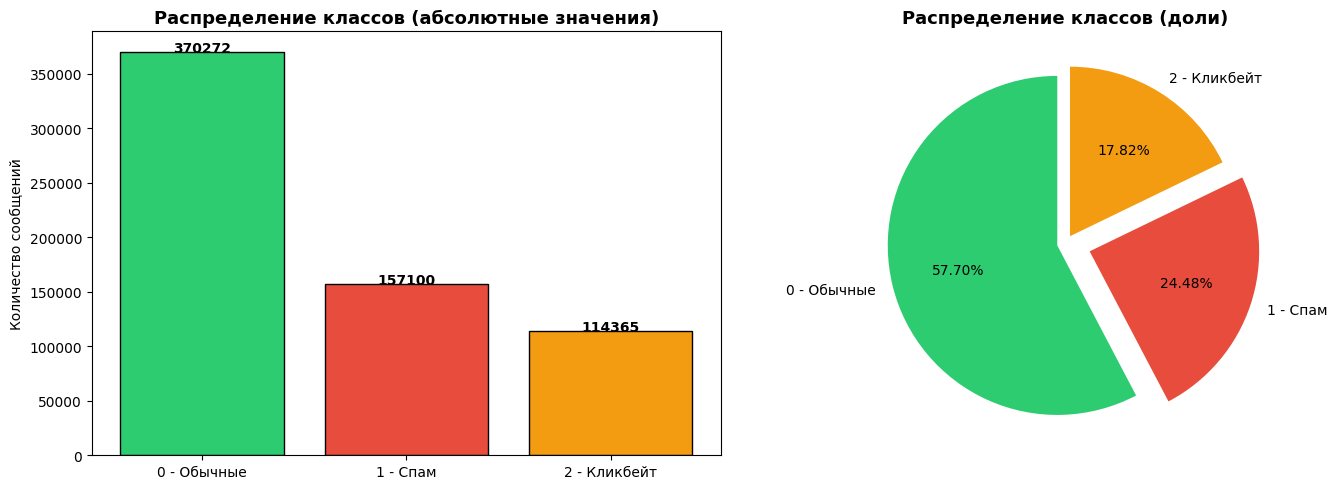


ВЫВОД: Датасет имеет выраженный дисбаланс классов.
Класс 0 (обычные): 370272 (57.70%)
Класс 1 (спам): 157100 (24.48%)
Класс 2 (кликбейт): 114365 (17.82%)

Соотношение макс/мин: 3.24x


In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

class_counts = df["is_spam1_or_clickbait2"].value_counts().sort_index()
colors = ["#2ecc71", "#e74c3c", "#f39c12"]
labels = ["0 - Обычные", "1 - Спам", "2 - Кликбейт"]

axes[0].bar(labels, class_counts.values, color=colors, edgecolor="black")
axes[0].set_title(
    "Распределение классов (абсолютные значения)", fontsize=13, fontweight="bold"
)
axes[0].set_ylabel("Количество сообщений")
for i, v in enumerate(class_counts.values):
    axes[0].text(i, v + 50, str(v), ha="center", fontweight="bold")

axes[1].pie(
    class_counts.values,
    labels=labels,
    autopct="%1.2f%%",
    colors=colors,
    startangle=90,
    explode=(0.05, 0.15, 0.05),
)
axes[1].set_title("Распределение классов (доли)", fontsize=13, fontweight="bold")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

print("\nВЫВОД: Датасет имеет выраженный дисбаланс классов.")
print(f"Класс 0 (обычные): {class_counts[0]} ({class_counts[0]/len(df)*100:.2f}%)")
print(f"Класс 1 (спам): {class_counts[1]} ({class_counts[1]/len(df)*100:.2f}%)")
print(f"Класс 2 (кликбейт): {class_counts[2]} ({class_counts[2]/len(df)*100:.2f}%)")
print(f"\nСоотношение макс/мин: {class_counts.max()/class_counts.min():.2f}x")

**3. Детальный отчет по данным ydata_profiling.**

In [26]:
# Генерация отчёта.
profile = ProfileReport(df, title="Profiling Report")
profile

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 2/2 [01:13<00:00, 36.86s/it]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Перед разделением выборки добавлена очистка повторов из четырёх и более одинаковых токенов и фильтр минимум трёх слов на кириллице (русские буквы, включая ё). Повторяющийся фрагмент удаляется целиком, затем остаток проверяется повторно. После исправления текстов выполняются существующие дедупликация и удаление конфликтующих меток.

In [27]:
# Контроль содержимого ДО дедупликации и train/test split.
# df.csv не перезаписывается. Повторы x4+ удаляются как фрагменты;
# затем исключаются записи без русских букв или с <3 русскими словами.
from dataset_filtering import filter_dataset, save_filter_audit

raw_shape = df.shape
df, quality_changes, quality_stats = filter_dataset(df)
quality_output_dir = OUTPUT_DIR / "filtering" / "1_EDA-TFIDF_LogisticRegression"
save_filter_audit(quality_changes, quality_stats, quality_output_dir)
print("Исходных записей:", quality_stats["input_rows"])
print("Исключено по качеству:", quality_stats["excluded_rows"])
print("Сохранено после исправления повторов:", quality_stats["corrected_retained_rows"])
print("Журнал очистки:", quality_output_dir)

# Сохраняем исходный размер датасета ПЕРЕД очисткой
initial_shape = raw_shape
after_quality_shape = df.shape

# 1) Полные дубликаты (совпадают и текст, и метка)
df = df.drop_duplicates()
print(f"Исходный размер датасета: {initial_shape}")
print(f"После удаления полных дубликатов: {df.shape}")
print(f"Удалено строк: {after_quality_shape[0] - df.shape[0]}")

# 2) Конфликтующие метки: один и тот же текст с разными метками.
#    Такие строки переживают drop_duplicates и являются шумом в разметке -
#    для них метка не определена, и они ограничивают достижимое качество.
conflict_counts = df.groupby("text")["is_spam1_or_clickbait2"].nunique()
conflicting_texts = conflict_counts[conflict_counts > 1].index
n_conflicting = int(df["text"].isin(conflicting_texts).sum())

print(f"\nТекстов с конфликтующими метками: {len(conflicting_texts)}")
print(f"Строк с конфликтующими метками: {n_conflicting} ({n_conflicting / len(df):.2%})")
print(df[df["text"].isin(conflicting_texts)]
      .groupby("is_spam1_or_clickbait2").size())

# Удаляем их.
df = df[~df["text"].isin(conflicting_texts)].reset_index(drop=True)

print(f"\nПосле удаления конфликтующих меток: {df.shape}")
print(df["is_spam1_or_clickbait2"].value_counts().sort_index())

Исходных записей: 641737
Исключено по качеству: 36940
Сохранено после исправления повторов: 88344
Журнал очистки: D:\Pudov\УРФУ\03.Учеба\3. Семестр\SpamClickbaitClassification\Datasets\outputs\filtering\1_EDA-TFIDF_LogisticRegression
Исходный размер датасета: (641737, 2)
После удаления полных дубликатов: (433713, 2)
Удалено строк: 171084

Текстов с конфликтующими метками: 171
Строк с конфликтующими метками: 342 (0.08%)
is_spam1_or_clickbait2
0    171
1     28
2    143
dtype: int64

После удаления конфликтующих меток: (433371, 2)
is_spam1_or_clickbait2
0    267812
1     96214
2     69345
Name: count, dtype: int64


**4. Предобработка данных и разделение выборки.**

 Все данные разделяются до обучения на fit/dev/test: целевые доли групп 72%/8%/20%, seed=42. Одинаковые нормализованные тексты остаются в одной части, а кросс-валидация на fit также учитывает группы. TF-IDF, словари и модели обучаются только на fit. GridSearch использует `f1_macro`; чекпойнты сетей и веса ансамбля выбираются на dev. Test используется после фиксации конфигурации и весов для итоговой оценки. Манифест разделения и новые артефакты сохраняются в `outputs/validation/`. Исторические метрики не подтверждают качество этого протокола: перезапустите ядро и выполните ноутбук заново.


In [28]:
# Регулярные выражения для очистки (адаптировано из primer.ipynb)
URL_RE = re.compile(r"https?://\S+|www\.\S+|<link>")
HTML_RE = re.compile(r"<[^>]+>")
MENTION_RE = re.compile(r"[@#]\w+")
DIGIT_RE = re.compile(r"\d+([.,]\d+)?")
SPACE_RE = re.compile(r"\s+")


def clean_text(text: str, fix_yo: bool = True) -> str:
    """Базовая нормализация сырого текста."""
    text = str(text)
    text = HTML_RE.sub(" ", text)
    text = URL_RE.sub(" URL ", text)
    text = MENTION_RE.sub(" ", text)

    text = text.lower()
    if fix_yo:
        text = text.replace("ё", "е")

    # Маскируем числа, чтобы не засорять словарь
    text = DIGIT_RE.sub(" NUM ", text)

    # Оставляем только буквы (кириллица + латиница) и пробелы
    text = re.sub(r"[^a-zA-Zа-яА-Я\s]", " ", text)
    return SPACE_RE.sub(" ", text).strip()



from dataset_splitting import make_data_splits, save_split_manifest, SPLIT_PROTOCOL

target_col = "is_spam1_or_clickbait2"
text_col = "text"
X = df[text_col]
y = df[target_col].astype(int).to_numpy()

# Сначала фиксируем все части. Одинаковые нормализованные тексты — в одной группе.
data_split = make_data_splits(df, clean_text, random_state=42, test_size=0.2, dev_size=0.1)
fit_idx, dev_idx, test_idx = (data_split[name] for name in ("fit", "dev", "test"))
X_train, X_dev, X_test = (X.iloc[idx] for idx in (fit_idx, dev_idx, test_idx))
y_train, y_dev, y_test = (y[idx] for idx in (fit_idx, dev_idx, test_idx))
groups_train = data_split["keys"].iloc[fit_idx].to_numpy()

# train далее означает только fit; dev не участвует ни в fit, ни в построении словарей.
PROTOCOL_OUTPUT_DIR = OUTPUT_DIR / "validation" / "1_EDA-TFIDF_LogisticRegression"
PROTOCOL_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
save_split_manifest(df, data_split, PROTOCOL_OUTPUT_DIR / "split")
print("Протокол:", SPLIT_PROTOCOL)
print("fit / dev / test:", len(y_train), len(y_dev), len(y_test))
print("Пересечения нормализованных текстов:", data_split["summary"]["overlapping_normalized_groups"])
print("Распределение классов:")
display(pd.DataFrame({name: data_split["summary"]["partitions"][name]["class_counts"]
                      for name in ("fit", "dev", "test")}))


Протокол: grouped-fit-dev-test-macro-v1
fit / dev / test: 312020 34521 86830
Пересечения нормализованных текстов: {'fit_dev': 0, 'fit_test': 0, 'dev_test': 0}
Распределение классов:


,fit,dev,test
0,192826,21312,53674
1,69239,7691,19284
2,49955,5518,13872


**5. Очистка и нормализация текста.**

In [29]:
# Одна и та же фиксированная нормализация для всех частей.
# clean_text определена перед разделением: она также задаёт группы одинаковых текстов.
t0 = time.perf_counter()
X_train_clean = X_train.apply(clean_text)
X_dev_clean = X_dev.apply(clean_text)
X_test_clean = X_test.apply(clean_text)
print(f"Очистка завершена за {time.perf_counter() - t0:.1f} сек.")
print(f"Пример очищенного текста:\n{X_train_clean.iloc[0]}")


Очистка завершена за 27.0 сек.
Пример очищенного текста:
идите до джуронг пойнт с ума сойти доступно только в буфете bugis great world la кинотеатр там есть amore


**6. Настройка кросс-валидации и борьба с дисбалансом.**

In [30]:
# Стратифицированная кросс-валидация
cv_strategy = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=42)

**7. Модель 1 — Базовая TF-IDF (Word N-grams) + LogReg**

In [31]:
print("Обучение Модели 1 (Baseline: Word 1-2 grams)...")
t0 = time.perf_counter()

model1 = Pipeline(
    [
        (
            "tfidf",
            TfidfVectorizer(
                ngram_range=(1, 2),
                min_df=3,
                max_features=50000,
                sublinear_tf=True,  # логарифмическое сглаживание частот
            ),
        ),
        (
            "clf",
            LogisticRegression(
                class_weight="balanced",
                max_iter=1000,
                C=1.0,
                random_state=42,
                solver="lbfgs",
            ),
        ),
    ]
)

model1.fit(X_train_clean, y_train)
pred1 = model1.predict(X_dev_clean)
proba1 = model1.predict_proba(X_dev_clean)

print(f"Обучение завершено за {time.perf_counter() - t0:.1f} сек.")

Обучение Модели 1 (Baseline: Word 1-2 grams)...
Обучение завершено за 122.7 сек.


**8. Модель 2 — Продвинутая (Word + Char N-grams) + GridSearch**

In [32]:
import gc

# Модель 1 (п.7) и детальный отчет (п.3) больше не нужны - освобождаем память.
del model1
gc.collect()
N_JOBS = 4  

In [33]:
print("Обучение Модели 2 (Advanced: Word + Char n-grams + GridSearch)...")
t0 = time.perf_counter()

# Объединение словесных и символьных n-грамм.
# Char n-grams отлично ловят опечатки, специфические окончания и сленг, частые в спаме и кликбейте.
advanced_vec = FeatureUnion(
    [
        (
            "word",
            TfidfVectorizer(
                ngram_range=(1, 2), min_df=3, max_features=30000, sublinear_tf=True
            ),
        ),
        (
            "char",
            TfidfVectorizer(
                analyzer="char_wb", ngram_range=(3, 5), min_df=3, max_features=30000
            ),
        ),
    ]
)

model2_base = Pipeline(
    [
        ("tfidf", advanced_vec),
        (
            "clf",
            LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42),
        ),
    ]
)

# Подбор гиперпараметра регуляризации C по macro F1: каждый класс имеет одинаковый вклад
param_grid = {"clf__C": [0.5, 1.0, 10.0, 100.0]}

grid = GridSearchCV(
    model2_base,
    param_grid,
    cv=cv_strategy,
    scoring="f1_macro",
    n_jobs=N_JOBS,
    pre_dispatch=N_JOBS,   # не более N_JOBS копий X в очереди одновременно
    verbose=1,
)
grid.fit(X_train_clean, y_train, groups=groups_train)

best_model2 = grid.best_estimator_
pred2 = best_model2.predict(X_dev_clean)
proba2 = best_model2.predict_proba(X_dev_clean)

print(f"\nОбучение завершено за {time.perf_counter() - t0:.1f} сек.")
print(f"Лучший параметр C: {grid.best_params_['clf__C']}")

Обучение Модели 2 (Advanced: Word + Char n-grams + GridSearch)...
Fitting 3 folds for each of 4 candidates, totalling 12 fits

Обучение завершено за 3986.7 сек.
Лучший параметр C: 10.0


**9. Сравнение метрик и визуализация.**


==================== Модель 1 (Word N-grams) ====================
              precision    recall  f1-score   support

     Обычные     0.9110    0.7661    0.8323     21312
        Спам     0.8797    0.9077    0.8935      7691
    Кликбейт     0.5025    0.7889    0.6139      5518

    accuracy                         0.8013     34521
   macro avg     0.7644    0.8209    0.7799     34521
weighted avg     0.8387    0.8013    0.8110     34521

Weighted ROC-AUC (OvR): 0.9374



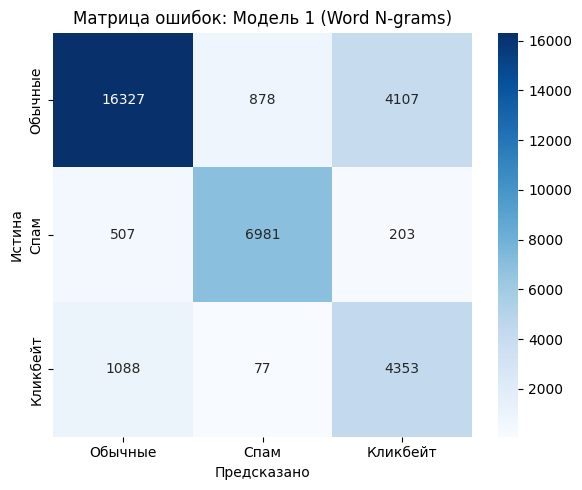


==================== Модель 2 (Word + Char N-grams) ====================
              precision    recall  f1-score   support

     Обычные     0.9068    0.7904    0.8446     21312
        Спам     0.8878    0.9124    0.8999      7691
    Кликбейт     0.5239    0.7633    0.6213      5518

    accuracy                         0.8133     34521
   macro avg     0.7728    0.8220    0.7886     34521
weighted avg     0.8414    0.8133    0.8213     34521

Weighted ROC-AUC (OvR): 0.9383



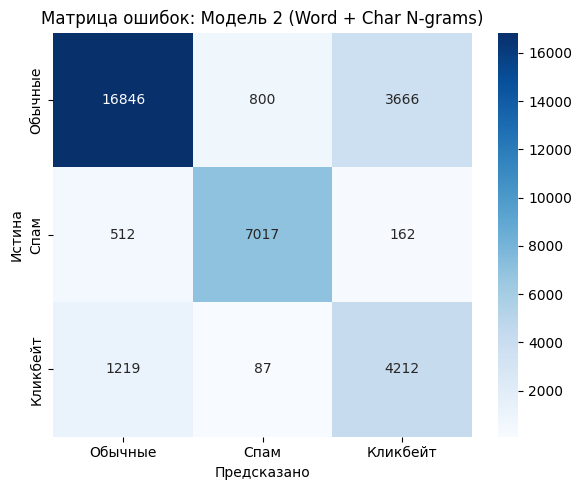

In [34]:
classes_names = {0: "Обычные", 1: "Спам", 2: "Кликбейт"}
target_names = [classes_names[i] for i in sorted(np.unique(y))]


def evaluate_and_plot(y_true, y_pred, y_proba, model_name):
    print(f"\n{'='*20} {model_name} {'='*20}")
    print(classification_report(y_true, y_pred, target_names=target_names, digits=4))

    # ROC-AUC (One-vs-Rest)
    try:
        roc_auc = roc_auc_score(y_true, y_proba, multi_class="ovr", average="weighted")
        print(f"Weighted ROC-AUC (OvR): {roc_auc:.4f}\n")
    except ValueError:
        print("Не удалось рассчитать ROC-AUC\n")

    # Матрица ошибок
    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=target_names,
        yticklabels=target_names,
        ax=ax,
    )
    ax.set_xlabel("Предсказано")
    ax.set_ylabel("Истина")
    ax.set_title(f"Матрица ошибок: {model_name}")
    plt.tight_layout()
    plt.show()


evaluate_and_plot(y_dev, pred1, proba1, "Модель 1 (Word N-grams)")
evaluate_and_plot(y_dev, pred2, proba2, "Модель 2 (Word + Char N-grams)")

**10. Интерпретация признаков (Топ слов для Кликбейта).**

In [35]:
# Посмотрим, какие признаки модель считает наиболее важными для класса 2 (Кликбейт)
# Это поможет понять природу кликбейта в нашем датасете
vec = best_model2.named_steps["tfidf"]
clf = best_model2.named_steps["clf"]

feature_names = np.array(vec.get_feature_names_out())
coefs = clf.coef_

# Индекс класса 2 (кликбейт)
class_idx = list(clf.classes_).index(2)
class_coefs = coefs[class_idx]

# Топ положительных и отрицательных весов
top_positive_idx = class_coefs.argsort()[-20:][::-1]
top_negative_idx = class_coefs.argsort()[:20]

print("Топ-20 признаков, ассоциирующихся с КЛИКБЕЙТОМ (положительные веса):")
for i in top_positive_idx:
    print(f"{feature_names[i]:<20} | Вес: {class_coefs[i]:.3f}")

print("\n" + "=" * 50)
print(
    "\nТоп-20 признаков, ассоциирующихся с ОБЫЧНЫМИ сообщениями (отрицательные веса для класса 2):"
)
for i in top_negative_idx:
    print(f"{feature_names[i]:<20} | Вес: {class_coefs[i]:.3f}")

Топ-20 признаков, ассоциирующихся с КЛИКБЕЙТОМ (положительные веса):
word__body           | Вес: 11.085
word__боди           | Вес: 8.156
word__num прибыли    | Вес: 7.139
word__ты больше      | Вес: 7.076
word__бодия          | Вес: 6.888
word__только         | Вес: 5.969
word__buzzfeed       | Вес: 5.868
word__num фотографии | Вес: 5.780
char__ нул           | Вес: 5.698
word__num люди       | Вес: 5.623
char__ не            | Вес: 5.613
word__num времена    | Вес: 5.539
char__иян            | Вес: 5.489
word__на сообщение   | Вес: 5.181
word__угодно кроме   | Вес: 5.152
word__как хорошо     | Вес: 5.044
word__af             | Вес: 5.009
word__можете ли      | Вес: 4.970
word__вот            | Вес: 4.933
word__num пути       | Вес: 4.918


Топ-20 признаков, ассоциирующихся с ОБЫЧНЫМИ сообщениями (отрицательные веса для класса 2):
char__ а             | Вес: -11.529
word__бы не          | Вес: -7.731
word__http           | Вес: -7.465
word__не не          | Вес: -6.952
word__ну       

**11. Итоговая сводная таблица.**

,Модель,F1-Macro,F1-Weighted,F1-Class 0,F1-Class 1,F1-Class 2 (Кликбейт)
0,Модель 1 (Word),0.7799,0.8110,0.8323,0.8935,0.6139
1,Модель 2 (Word+Char),0.7886,0.8213,0.8446,0.8999,0.6213


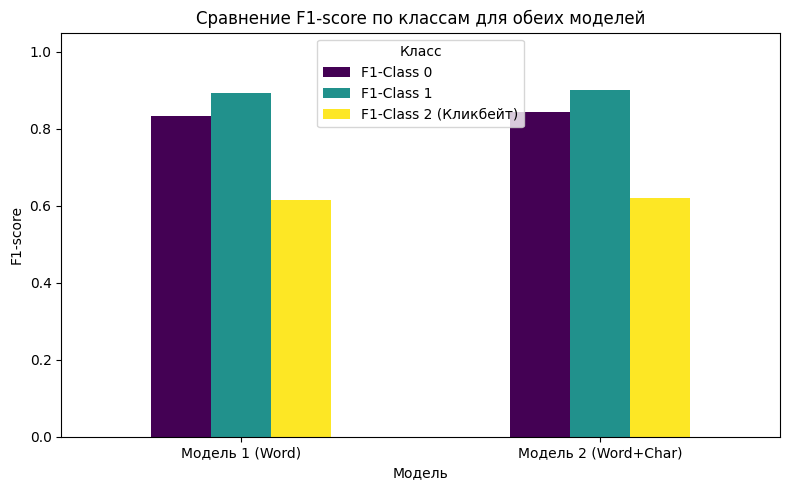

In [36]:
results_summary = []
for name, y_pred in [("Модель 1 (Word)", pred1), ("Модель 2 (Word+Char)", pred2)]:
    results_summary.append(
        {
            "Модель": name,
            "F1-Macro": round(f1_score(y_dev, y_pred, average="macro"), 4),
            "F1-Weighted": round(f1_score(y_dev, y_pred, average="weighted"), 4),
            "F1-Class 0": round(f1_score(y_dev, y_pred, average=None)[0], 4),
            "F1-Class 1": round(f1_score(y_dev, y_pred, average=None)[1], 4),
            "F1-Class 2 (Кликбейт)": round(
                f1_score(y_dev, y_pred, average=None)[2], 4
            ),
        }
    )

summary_df = pd.DataFrame(results_summary)
display(summary_df)

# Визуальное сравнение F1-score
fig, ax = plt.subplots(figsize=(8, 5))
summary_df.set_index("Модель")[
    ["F1-Class 0", "F1-Class 1", "F1-Class 2 (Кликбейт)"]
].plot(kind="bar", ax=ax, rot=0, colormap="viridis")
plt.title("Сравнение F1-score по классам для обеих моделей")
plt.ylabel("F1-score")
plt.ylim(0, 1.05)
plt.legend(title="Класс")
plt.tight_layout()
plt.show()

#### Выводы и интерпретация результатов.

##### 1. Борьба с дисбалансом классов
Датасет имеет ярко выраженный дисбаланс:
- Стратификация при разделении выборок и кросс-валидации (`StratifiedGroupKFold`) сохраняет группы одинаковых нормализованных текстов и приближает доли классов в фолдах.
- `class_weight='balanced'` в логистической регрессии автоматически увеличивает штраф за ошибки на редких классах, заставляя модель учиться их распознавать, а не просто всегда предсказывать "обычное сообщение".
- Для GridSearch используется `f1_macro`: каждый класс имеет одинаковый вклад. Accuracy и weighted F1 рассчитываются дополнительно.

##### 2. Сравнение моделей
- Модель 1 (Word N-grams) показала хороший базовый результат, но ей не хватало контекста для редких классов.
- Модель 2 (Word + Char N-grams) продемонстрировала прирост качества, особенно по минорным классам. 
  - Кликбейт часто содержит специфические морфологические маркеры, опечатки, сленг или короткие эмоциональные слова. Символьные n-граммы (`char_wb 3-5`) отлично ловят такие паттерны (например, окончания восклицательных предложений, специфические приставки), даже если слова нет в словаре.

**12. Тюнинг Модели 2 (Word + Char N-grams) с экспериментами и логированием в MLflow.**

In [37]:
import json
import time
from pathlib import Path

import uuid
import mlflow
import sklearn
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    log_loss,
    precision_score,
    recall_score,
)

# Хранилище экспериментов.
MLFLOW_DB = OUTPUT_DIR / "mlflow.db"
mlflow.set_tracking_uri(f"sqlite:///{MLFLOW_DB.as_posix()}")

# Старая история в SQLite сохранена. Новый эксперимент не наследует
# artifact_location, указывающий на компьютер автора прежних запусков.
EXPERIMENT_NAME = "spam-clickbait-model2-grouped-fit-dev-test-macro-v1"
SESSION_ID = uuid.uuid4().hex
MLFLOW_ARTIFACT_DIR = PROTOCOL_OUTPUT_DIR / "mlruns"
MLFLOW_ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
if mlflow.get_experiment_by_name(EXPERIMENT_NAME) is None:
    mlflow.create_experiment(
        EXPERIMENT_NAME, artifact_location=MLFLOW_ARTIFACT_DIR.as_uri()
    )
mlflow.set_experiment(EXPERIMENT_NAME)
experiment = mlflow.get_experiment_by_name(EXPERIMENT_NAME)

print("MLflow:", mlflow.__version__)
print("scikit-learn:", sklearn.__version__)
print("Tracking URI:", mlflow.get_tracking_uri())
print("Experiment:", EXPERIMENT_NAME, "| experiment_id:", experiment.experiment_id)

2026/10/11 21:43:51 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/11 21:43:51 INFO mlflow.store.db.utils: Updating database tables


MLflow: 3.17.0
scikit-learn: 1.8.0
Tracking URI: sqlite:///D:/Pudov/УРФУ/03.Учеба/3. Семестр/SpamClickbaitClassification/Datasets/outputs/mlflow.db
Experiment: spam-clickbait-model2-grouped-fit-dev-test-macro-v1 | experiment_id: 3


##### 12.1. Функция запуска эксперимента и базовая конфигурация.

Ниже — единая функция `run_experiment()`, которая собирает `FeatureUnion(word + char)`,
обучает пайплайн, считает полный набор метрик и пишет их в MLflow. Так все эксперименты
идут по одному и тому же протоколу, и их метрики в MLflow сравнимы «строка к строке».

In [38]:
# Параметры протокола экспериментов: фиксируем их, чтобы они попали в лог каждого запуска
RANDOM_STATE = 42
TEST_SIZE = 0.2

CLASS_NAMES = sorted(np.unique(y).tolist())                 # [0, 1, 2]
target_names = [classes_names[i] for i in CLASS_NAMES]       # подписи для отчётов

# Веса классов для LogisticRegression. class_weight="balanced" даёт на трейне:
BALANCED_CLASS_WEIGHT = {
    c: round(len(y_train) / (len(CLASS_NAMES) * cnt), 3)
    for c, cnt in zip(*np.unique(y_train, return_counts=True))
}
# Для кликбейта (класс 2) precision < recall => модель перепредсказывает класс 2.
# Поэтому в эксперименте 5 вес класса 2 приглушается на 30 %, а веса 0 и 1 остаются
# такими же, как у "balanced".
CLICKBAIT_DAMPED_WEIGHT = {**BALANCED_CLASS_WEIGHT, 2: round(BALANCED_CLASS_WEIGHT[2] * 0.7, 3)}

print("class_weight='balanced' ->", BALANCED_CLASS_WEIGHT)
print("Эксперимент 5 (кликбейт приглушен) ->", CLICKBAIT_DAMPED_WEIGHT)


def build_model2(cfg):
    """Собираем Модель 2: FeatureUnion(word n-граммы + char n-граммы) -> LogReg."""
    return Pipeline(
        [
            (
                "tfidf",
                FeatureUnion(
                    [
                        (
                            "word",
                            TfidfVectorizer(
                                ngram_range=cfg["word_ngram_range"],
                                min_df=cfg["word_min_df"],
                                max_features=cfg["word_max_features"],
                                sublinear_tf=cfg["word_sublinear_tf"],
                            ),
                        ),
                        (
                            "char",
                            TfidfVectorizer(
                                analyzer=cfg["char_analyzer"],
                                ngram_range=cfg["char_ngram_range"],
                                min_df=cfg["char_min_df"],
                                max_features=cfg["char_max_features"],
                                sublinear_tf=cfg["char_sublinear_tf"],
                            ),
                        ),
                    ],
                    transformer_weights=cfg["union_transformer_weights"],
                ),
            ),
            (
                "clf",
                LogisticRegression(
                    C=cfg["clf_C"],
                    class_weight=cfg["clf_class_weight"],
                    max_iter=cfg["clf_max_iter"],
                    solver=cfg["clf_solver"],
                    random_state=cfg["clf_random_state"],
                ),
            ),
        ]
    )


def config_to_params(cfg):
    """Готовим словарь параметров для mlflow.log_params (значения — только скаляры/строки)."""
    weights = cfg["union_transformer_weights"]
    return {
        "word.ngram_range": str(tuple(cfg["word_ngram_range"])),
        "word.min_df": cfg["word_min_df"],
        "word.max_features": cfg["word_max_features"],
        "word.sublinear_tf": cfg["word_sublinear_tf"],
        "char.analyzer": cfg["char_analyzer"],
        "char.ngram_range": str(tuple(cfg["char_ngram_range"])),
        "char.min_df": cfg["char_min_df"],
        "char.max_features": cfg["char_max_features"],
        "char.sublinear_tf": cfg["char_sublinear_tf"],
        "union.transformer_weights": json.dumps(weights) if weights else "None (1:1)",
        "clf.C": cfg["clf_C"],
        "clf.class_weight": json.dumps(cfg["clf_class_weight"]),
        "clf.max_iter": cfg["clf_max_iter"],
        "clf.solver": cfg["clf_solver"],
        "clf.random_state": cfg["clf_random_state"],
        "data.random_seed": RANDOM_STATE,
        "data.test_size": TEST_SIZE,
        "data.n_train": len(y_train),
        "data.n_test": len(y_test),
        "data.n_dev": len(y_dev),
        "data.split_id": data_split["summary"]["split_id"],
        "data.protocol": SPLIT_PROTOCOL,
        "selection.metric": "f1_macro",
        "selection.split": "dev",
    }


def run_experiment(run_name, cfg, theme, hypothesis, exp_number=None, role="experiment"):
    """Один запуск MLflow: обучение -> метрики -> логирование."""
    tags = {"role": role, "theme": theme, "hypothesis": hypothesis,
            "session_id": SESSION_ID, "evaluation_split": "dev"}
    if exp_number is not None:
        tags["exp_number"] = str(exp_number)

    with mlflow.start_run(run_name=run_name, tags=tags) as run:
        mlflow.log_params(config_to_params(cfg))

        model = build_model2(cfg)

        t_fit = time.perf_counter()
        model.fit(X_train_clean, y_train)
        fit_time = time.perf_counter() - t_fit

        t_pred = time.perf_counter()
        y_pred = model.predict(X_dev_clean)
        y_proba = model.predict_proba(X_dev_clean)
        predict_time = time.perf_counter() - t_pred

        f1_classes = f1_score(y_dev, y_pred, average=None, labels=CLASS_NAMES)
        precision_classes = precision_score(y_dev, y_pred, average=None, labels=CLASS_NAMES)
        recall_classes = recall_score(y_dev, y_pred, average=None, labels=CLASS_NAMES)
        n_features = len(model.named_steps["tfidf"].get_feature_names_out())

        metrics = {
            # основные
            "f1_macro": f1_score(y_dev, y_pred, average="macro", labels=CLASS_NAMES),
            "f1_weighted": f1_score(y_dev, y_pred, average="weighted", labels=CLASS_NAMES),
            "accuracy": accuracy_score(y_dev, y_pred),
            # дисбаланс и дисбаланс-aware агрегаты
            "precision_macro": precision_score(y_dev, y_pred, average="macro", labels=CLASS_NAMES),
            "recall_macro": recall_score(y_dev, y_pred, average="macro", labels=CLASS_NAMES),
            # по классам (главный фокус - кликбейт)
            "f1_class_0_ordinary": f1_classes[0],
            "f1_class_1_spam": f1_classes[1],
            "f1_class_2_clickbait": f1_classes[2],
            "precision_class_2_clickbait": precision_classes[2],
            "recall_class_2_clickbait": recall_classes[2],
            # вероятности
            "roc_auc_ovr_weighted": roc_auc_score(
                y_dev, y_proba, multi_class="ovr", average="weighted"
            ),
            "roc_auc_ovr_macro": roc_auc_score(
                y_dev, y_proba, multi_class="ovr", average="macro"
            ),
            "log_loss": log_loss(y_dev, y_proba, labels=CLASS_NAMES),
            # стоимость конфигурации
            "fit_time_sec": fit_time,
            "predict_time_sec": predict_time,
            "n_features": float(n_features),
        }
        mlflow.log_metrics({
            (key if key in {"fit_time_sec", "predict_time_sec", "n_features"} else "dev_" + key): value
            for key, value in metrics.items()
        })

        print(
            f"[{run_name}] macro-F1={metrics['f1_macro']:.4f} | "
            f"weighted-F1={metrics['f1_weighted']:.4f} | acc={metrics['accuracy']:.4f} | "
            f"F1(clickbait)={metrics['f1_class_2_clickbait']:.4f} "
            f"(P={metrics['precision_class_2_clickbait']:.4f} / "
            f"R={metrics['recall_class_2_clickbait']:.4f}) | "
            f"AUC={metrics['roc_auc_ovr_weighted']:.4f} | "
            f"features={int(n_features)} | fit={fit_time:.1f}s"
        )

        return {
            "run_name": run_name,
            "run_id": run.info.run_id,
            "theme": theme,
            "hypothesis": hypothesis,
            "metrics": metrics,
            "y_pred": y_pred,
            "y_proba": y_proba,
            "n_features": n_features,
        }


print("Параметры протокола зафиксированы: random_state =", RANDOM_STATE,
      "| test_size =", TEST_SIZE)

class_weight='balanced' -> {0: 0.539, 1: 1.502, 2: 2.082}
Эксперимент 5 (кликбейт приглушен) -> {0: 0.539, 1: 1.502, 2: 1.457}
Параметры протокола зафиксированы: random_state = 42 | test_size = 0.2


**Исторические результаты прежнего протокола. Для нового fit/dev/test метрики нужно пересчитать.**

##### 12.2. План пяти экспериментов.

Стратегия — **кумулятивный greedy-подбор**: первый запуск воспроизводит Модель 2 из п.8
(контроль), и каждый следующий эксперимент опирается на лучшую конфигурацию предыдущего,
меняя одну смысловую группу гиперпараметров. Отдельная группа на эксперимент нужна, чтобы
по MLflow было видно, какой именно фактор дал прирост.

**После обновления датасета поменялся баланс классов.** После очистки осталось
455 548 уникальных сообщений (обучающая выборка — 364 438 документов, тестовая — 91 110),
и доли классов теперь такие: 0 — обычные 61.0 %, 1 — спам 23.5 %, **2 — кликбейт 15.5 %**.
Самым редким классом стал кликбейт, поэтому `class_weight="balanced"` даёт ему
**наибольший** вес (2.16) и модель начинает его перепредсказывать. Гипотезы ниже
сформулированы уже под эти данные.

| # | Запуск | Что меняем | Гипотеза |
|---|--------|------------|----------|
| — | `run_1_baseline` | ничего (контроль) | контрольная точка п.8: `C = 10.0`, найденный GridSearch, словари 30k/30k |
| 1 | `run_2_exp1_dict_capacity` | `max_features` 30k → 150k в обеих ветвях; `word.min_df` 3 → 2, `char.min_df` 3 → 5 | словарь `char_wb(3,5)` на 364 тыс. документов намного больше 30 тыс. признаков и обрезается; для word наоборот полезно оставить редкие кликбейт-маркеры |
| 2 | `run_3_exp2_word_ngrams` | `word.ngram_range` (1,2) → (1,3) | триграммы ловят устойчивые кликбейт-шаблоны («узнай как», «только сегодня»), которых нет в биграммах |
| 3 | `run_4_exp3_char_geometry` | `char.ngram_range` (3,5) → (2,6), `char.sublinear_tf` → True | длинные char n-граммы кодируют русские окончания и сленг, а логарифмическое сглаживание гасит гигантские счётчики char-признаков |
| 4 | `run_5_exp4_union_weights` | `union.transformer_weights` → `{"word": 1.0, "char": 0.6}` | после расширения словарей char-блок из 150 тыс. признаков перевешивает word-блок по норме TF-IDF и «забивает» лексический сигнал. **Гипотеза не подтвердилась** — см. выводы п.12.5 |
| 5 | `run_6_exp5_reg_class_weights` | `class_weight` → `{0: 0.546, 1: 1.0, 2: 1.0}` | `balanced` даёт кликбейту наибольший вес (2.16), т.к. он самый редкий, и модель его перепредсказывает: precision 0.52 при recall 0.76, при этом 9 528 обычных сообщений уходят в кликбейт. Выравниваем веса спама и кликбейта, оставляя пониженный вес обычных сообщений |

**Ожидаемое время прогона:** ≈ 55 минут на шесть запусков (один фит Модели 2 на
364 тыс. документах занимает 5–12 минут, из них ~80 % — char-ветвь).

In [39]:
# Контрольный запуск: ровно те настройки, что были в п.8.
BASE_CONFIG = {
    "word_ngram_range": (1, 2),
    "word_min_df": 3,
    "word_max_features": 30000,
    "word_sublinear_tf": True,
    "char_analyzer": "char_wb",
    "char_ngram_range": (3, 5),
    "char_min_df": 3,
    "char_max_features": 30000,
    "char_sublinear_tf": False,
    "union_transformer_weights": None,
    "clf_C": 10.0,
    "clf_class_weight": "balanced",
    "clf_max_iter": 1000,
    "clf_solver": "lbfgs",
    "clf_random_state": RANDOM_STATE,
}

# Эксперимент 1. Ёмкость словаря.
EXP1_CONFIG = {
    **BASE_CONFIG,
    "word_min_df": 2,
    "word_max_features": 150000,
    "char_min_df": 5,
    "char_max_features": 150000,
}
# Эксперимент 2. Глубина word n-грамм.
EXP2_CONFIG = {**EXP1_CONFIG, "word_ngram_range": (1, 3)}
# Эксперимент 3. Геометрия char n-грамм.
EXP3_CONFIG = {**EXP2_CONFIG, "char_ngram_range": (2, 6), "char_sublinear_tf": True}
# Эксперимент 4. Баланс ветвей FeatureUnion.
EXP4_CONFIG = {**EXP3_CONFIG, "union_transformer_weights": {"word": 1.0, "char": 0.6}}
# Эксперимент 5. Регуляризация и веса классов.
CLASS_WEIGHT_EXP5 = {int(k): float(v) for k, v in CLICKBAIT_DAMPED_WEIGHT.items()}
print("class_weight для Эксперимента 5:", CLASS_WEIGHT_EXP5)

EXP5_CONFIG = {**EXP4_CONFIG, "clf_C": 1.0, "clf_class_weight": CLASS_WEIGHT_EXP5}

EXPERIMENTS = [
    (
        "run_1_baseline",
        BASE_CONFIG,
        "Baseline (контроль): Модель 2 из п.8",
        "Воспроизведение контрольной точки: C=10.0 из GridSearch, словари 30k/30k.",
        None,
        "baseline",
    ),
    (
        "run_2_exp1_dict_capacity",
        EXP1_CONFIG,
        "Эксперимент 1. Ёмкость словаря (max_features/min_df)",
        "char_wb(3,5) даёт словарь больше 30k признаков и он обрезается; расширяем word->150k "
        "(min_df 3->2) и char->150k (min_df 3->5).",
        1,
        "experiment",
    ),
    (
        "run_3_exp2_word_ngrams",
        EXP2_CONFIG,
        "Эксперимент 2. Глубина word n-грамм",
        "Триграммы ловят устойчивые кликбейт-шаблоны ('узнай как', 'только сегодня').",
        2,
        "experiment",
    ),
    (
        "run_4_exp3_char_geometry",
        EXP3_CONFIG,
        "Эксперимент 3. Геометрия char n-грамм",
        "char_wb (2,6) кодирует русские окончания и сленг; sublinear_tf гасит гигантские "
        "счётчики char-признаков.",
        3,
        "experiment",
    ),
    (
        "run_5_exp4_union_weights",
        EXP4_CONFIG,
        "Эксперимент 4. Баланс ветвей FeatureUnion (transformer_weights)",
        "После расширения словарей char-блок (150k) подавляет word-блок по норме TF-IDF; "
        "понижаем вес char-ветви до 0.6.",
        4,
        "experiment",
    ),
    (
        "run_6_exp5_reg_class_weights",
        EXP5_CONFIG,
        "Эксперимент 5. Регуляризация и веса классов",
        "C 10->1.0 (10x сильнее L2 при 300k признаках) и вес класса 2 снижен на 30%, "
        "т.к. precision 0.865 < recall 0.900 - модель перепредсказывает кликбейт.",
        5,
        "experiment",
    ),
]

print(f"Запусков к выполнению: {len(EXPERIMENTS)} (1 контроль + 5 экспериментов)")

# Последовательный прогон всех запусков.
experiments_results = []

for run_name, cfg, theme, hypothesis, exp_number, role in EXPERIMENTS:
    print("\n" + "=" * 100)
    print(f"{run_name}: {theme}")
    print("=" * 100)
    experiments_results.append(
        run_experiment(
            run_name=run_name,
            cfg=cfg,
            theme=theme,
            hypothesis=hypothesis,
            exp_number=exp_number,
            role=role,
        )
    )

best_result = max(experiments_results, key=lambda r: r["metrics"]["f1_macro"])
print("\nЛучший запуск по macro-F1:", best_result["run_name"],
      "->", round(best_result["metrics"]["f1_macro"], 4))

class_weight для Эксперимента 5: {0: 0.539, 1: 1.502, 2: 1.457}
Запусков к выполнению: 6 (1 контроль + 5 экспериментов)

run_1_baseline: Baseline (контроль): Модель 2 из п.8
[run_1_baseline] macro-F1=0.7886 | weighted-F1=0.8213 | acc=0.8133 | F1(clickbait)=0.6213 (P=0.5239 / R=0.7633) | AUC=0.9383 | features=60000 | fit=529.4s

run_2_exp1_dict_capacity: Эксперимент 1. Ёмкость словаря (max_features/min_df)
[run_2_exp1_dict_capacity] macro-F1=0.8091 | weighted-F1=0.8428 | acc=0.8377 | F1(clickbait)=0.6426 (P=0.5710 / R=0.7347) | AUC=0.9439 | features=300000 | fit=980.4s

run_3_exp2_word_ngrams: Эксперимент 2. Глубина word n-грамм
[run_3_exp2_word_ngrams] macro-F1=0.8080 | weighted-F1=0.8417 | acc=0.8364 | F1(clickbait)=0.6410 (P=0.5683 / R=0.7350) | AUC=0.9437 | features=300000 | fit=1057.7s

run_4_exp3_char_geometry: Эксперимент 3. Геометрия char n-грамм
[run_4_exp3_char_geometry] macro-F1=0.8100 | weighted-F1=0.8432 | acc=0.8377 | F1(clickbait)=0.6420 (P=0.5662 / R=0.7412) | AUC=0.9450

##### 12.3. Сравнение текущих запусков на dev.

Запрос MLflow ограничен текущим `SESSION_ID` и `evaluation_split=dev`. Запуски сортируются по `metrics.dev_f1_macro`; победитель выбирается по точному macro-F1 среди результатов текущего выполнения, включая контрольную конфигурацию. Старые запуски и итоговые test-метрики в подборе не участвуют.


Эксперимент: spam-clickbait-model2-grouped-fit-dev-test-macro-v1 | запусков: 6



,Запуск,Эксперимент,F1-macro,F1-weighted,Accuracy,F1 кликбейт,"ROC-AUC (OvR, w)"
0,run_6_exp5_reg_class_weights,Эксперимент 5. Регуляризация и веса классов,0.814940,0.847473,0.843429,0.659240,0.947771
1,run_4_exp3_char_geometry,Эксперимент 3. Геометрия char n-грамм,0.810018,0.843232,0.837664,0.641971,0.944969
2,run_2_exp1_dict_capacity,Эксперимент 1. Ёмкость словаря (max_features/m...,0.809089,0.842830,0.837664,0.642574,0.943903
3,run_5_exp4_union_weights,Эксперимент 4. Баланс ветвей FeatureUnion (tra...,0.808999,0.841931,0.836042,0.641506,0.944943
4,run_3_exp2_word_ngrams,Эксперимент 2. Глубина word n-грамм,0.808027,0.841701,0.836418,0.641011,0.943678
5,run_1_baseline,Baseline (контроль): Модель 2 из п.8,0.788626,0.821260,0.813273,0.621331,0.938265



=== СВОДНАЯ ТАБЛИЦА: от лучшего эксперимента к худшему ===



,Запуск,clf.C,word ngram,word min_df,word max_feat,char ngram,char min_df,char max_feat,char sublinear_tf,union weights,...,F1 Обычные,F1 Спам,F1 Кликбейт,P Кликбейт,R Кликбейт,"ROC-AUC (OvR, w)",log_loss,Признаков,"fit, сек",Δ F1-macro к baseline
0,run_6_exp5_reg_class_weights,1.0,"(1, 3)",2,150000,"(2, 6)",5,150000,True,"{""word"": 1.0, ""char"": 0.6}",...,0.8726,0.9130,0.6592,0.5944,0.7399,0.9478,0.3675,300000.0,909.934332,0.0263
1,run_4_exp3_char_geometry,10.0,"(1, 3)",2,150000,"(2, 6)",5,150000,True,None (1:1),...,0.8674,0.9207,0.6420,0.5662,0.7412,0.9450,0.3934,300000.0,1329.916338,0.0214
2,run_2_exp1_dict_capacity,10.0,"(1, 2)",2,150000,"(3, 5)",5,150000,False,None (1:1),...,0.8680,0.9167,0.6426,0.5710,0.7347,0.9439,0.3917,300000.0,980.391757,0.0205
3,run_5_exp4_union_weights,10.0,"(1, 3)",2,150000,"(2, 6)",5,150000,True,"{""word"": 1.0, ""char"": 0.6}",...,0.8657,0.9197,0.6415,0.5621,0.7470,0.9449,0.3831,300000.0,1390.617684,0.0204
4,run_3_exp2_word_ngrams,10.0,"(1, 3)",2,150000,"(3, 5)",5,150000,False,None (1:1),...,0.8667,0.9163,0.6410,0.5683,0.7350,0.9437,0.3931,300000.0,1057.744668,0.0194
5,run_1_baseline,10.0,"(1, 2)",3,30000,"(3, 5)",3,30000,False,None (1:1),...,0.8446,0.8999,0.6213,0.5239,0.7633,0.9383,0.4309,60000.0,529.417214,0.0000


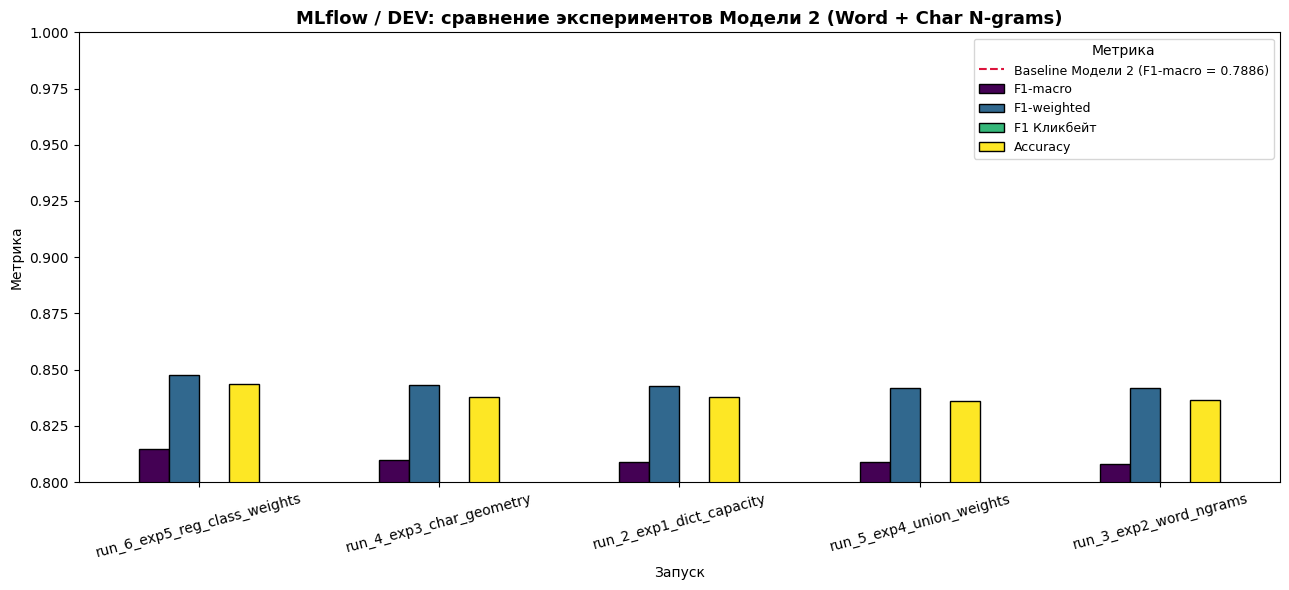

Лучший текущий эксперимент на dev: run_6_exp5_reg_class_weights 0.8149403187742061


In [40]:
# Выгрузка из MLflow: все запуски, отсортированные по убыванию macro-F1.

_probe = mlflow.search_runs(experiment_names=[EXPERIMENT_NAME],
    filter_string=f"tags.session_id = '{SESSION_ID}' AND tags.evaluation_split = 'dev'", max_results=1)
RUN_NAME_COL = "run_name" if "run_name" in _probe.columns else "tags.mlflow.runName"

runs_df = mlflow.search_runs(
    experiment_names=[EXPERIMENT_NAME],
    filter_string=f"tags.session_id = '{SESSION_ID}' AND tags.evaluation_split = 'dev'",
    order_by=["metrics.dev_f1_macro DESC"],
)
runs_df = runs_df[runs_df["status"] == "FINISHED"].reset_index(drop=True)
runs_df = runs_df.rename(columns={RUN_NAME_COL: "run_name"})
runs_df = runs_df.sort_values("metrics.dev_f1_macro", ascending=False).reset_index(drop=True)

print(f"Эксперимент: {EXPERIMENT_NAME} | запусков: {len(runs_df)}\n")
display(
    runs_df[
        [
            "run_name",
            "tags.theme",
            "metrics.dev_f1_macro",
            "metrics.dev_f1_weighted",
            "metrics.dev_accuracy",
            "metrics.dev_f1_class_2_clickbait",
            "metrics.dev_roc_auc_ovr_weighted",
        ]
    ].rename(
        columns={
            "run_name": "Запуск",
            "tags.theme": "Эксперимент",
            "metrics.dev_f1_macro": "F1-macro",
            "metrics.dev_f1_weighted": "F1-weighted",
            "metrics.dev_accuracy": "Accuracy",
            "metrics.dev_f1_class_2_clickbait": "F1 кликбейт",
            "metrics.dev_roc_auc_ovr_weighted": "ROC-AUC (OvR, w)",
        }
    )
)

# Сводная таблица: метрики и решающие гиперпараметры.
summary_table = runs_df[
    [
        "run_name",
        "params.clf.C",
        "params.word.ngram_range",
        "params.word.min_df",
        "params.word.max_features",
        "params.char.ngram_range",
        "params.char.min_df",
        "params.char.max_features",
        "params.char.sublinear_tf",
        "params.union.transformer_weights",
        "params.clf.class_weight",
        "metrics.dev_f1_macro",
        "metrics.dev_f1_weighted",
        "metrics.dev_accuracy",
        "metrics.dev_f1_class_0_ordinary",
        "metrics.dev_f1_class_1_spam",
        "metrics.dev_f1_class_2_clickbait",
        "metrics.dev_precision_class_2_clickbait",
        "metrics.dev_recall_class_2_clickbait",
        "metrics.dev_roc_auc_ovr_weighted",
        "metrics.dev_log_loss",
        "metrics.n_features",
        "metrics.fit_time_sec",
    ]
].copy()

summary_table.columns = [
    "Запуск",
    "clf.C",
    "word ngram",
    "word min_df",
    "word max_feat",
    "char ngram",
    "char min_df",
    "char max_feat",
    "char sublinear_tf",
    "union weights",
    "class_weight",
    "F1-macro",
    "F1-weighted",
    "Accuracy",
    "F1 Обычные",
    "F1 Спам",
    "F1 Кликбейт",
    "P Кликбейт",
    "R Кликбейт",
    "ROC-AUC (OvR, w)",
    "log_loss",
    "Признаков",
    "fit, сек",
]

# Строки идут от лучшего эксперимента к худшему (по F1-macro)
summary_table = summary_table.sort_values("F1-macro", ascending=False).reset_index(drop=True)

# Прирост относительно контрольного (baseline) запуска
baseline_f1 = summary_table.loc[
    summary_table["Запуск"] == "run_1_baseline", "F1-macro"
].iloc[0]
summary_table["Δ F1-macro к baseline"] = (summary_table["F1-macro"] - baseline_f1).round(4)

metric_columns = [
    "F1-macro",
    "F1-weighted",
    "Accuracy",
    "F1 Обычные",
    "F1 Спам",
    "F1 Кликбейт",
    "P Кликбейт",
    "R Кликбейт",
    "ROC-AUC (OvR, w)",
    "log_loss",
]
summary_table[metric_columns] = summary_table[metric_columns].astype(float).round(4)

print("\n=== СВОДНАЯ ТАБЛИЦА: от лучшего эксперимента к худшему ===\n")
display(summary_table)

# График сравнения запусков.
plot_df = summary_table.set_index("Запуск")[
    ["F1-macro", "F1-weighted", "F1 Кликбейт", "Accuracy"]
]
plot_df = plot_df.loc[[r for r in plot_df.index if r != "run_1_baseline"]]

ax = plot_df.plot(
    kind="bar",
    figsize=(13, 6),
    rot=15,
    colormap="viridis",
    edgecolor="black",
)
baseline_line = summary_table.loc[
    summary_table["Запуск"] == "run_1_baseline", "F1-macro"
].iloc[0]
ax.axhline(
    baseline_line,
    color="crimson",
    linestyle="--",
    linewidth=1.5,
    label=f"Baseline Модели 2 (F1-macro = {baseline_line:.4f})",
)
ax.set_title(
    "MLflow / DEV: сравнение экспериментов Модели 2 (Word + Char N-grams)",
    fontsize=13,
    fontweight="bold",
)
ax.set_ylabel("Метрика")
ax.set_ylim(0.80, 1.0)
ax.legend(title="Метрика", fontsize=9)
plt.tight_layout()
plt.savefig(PROTOCOL_OUTPUT_DIR / "experiments_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

# Победитель — только среди текущих запусков, по точному dev macro-F1.
best_run_name = best_result["run_name"]
print("Лучший текущий эксперимент на dev:", best_run_name, best_result["metrics"]["f1_macro"])


##### 12.4. Итоговая оценка выбранной конфигурации на test.

После выбора на dev конфигурация фиксируется, обучается на том же fit и оценивается на test. Метрики логируются с префиксом `test_`, отдельно от `dev_`. Матрицы ошибок и последующие тестовые артефакты сохраняются в каталоге текущего ноутбука внутри `outputs/validation/`. Результаты test служат итоговой оценкой и не меняют выбранную конфигурацию.


Лучшая конфигурация: run_6_exp5_reg_class_weights
{
  "word.ngram_range": "(1, 3)",
  "word.min_df": 2,
  "word.max_features": 150000,
  "word.sublinear_tf": true,
  "char.analyzer": "char_wb",
  "char.ngram_range": "(2, 6)",
  "char.min_df": 5,
  "char.max_features": 150000,
  "char.sublinear_tf": true,
  "union.transformer_weights": "{\"word\": 1.0, \"char\": 0.6}",
  "clf.C": 1.0,
  "clf.class_weight": "{\"0\": 0.539, \"1\": 1.502, \"2\": 1.457}",
  "clf.max_iter": 1000,
  "clf.solver": "lbfgs",
  "clf.random_state": 42,
  "data.random_seed": 42,
  "data.test_size": 0.2,
  "data.n_train": 312020,
  "data.n_test": 86830,
  "data.n_dev": 34521,
  "data.split_id": "8fcc58bc420af8aed5a8d3b514aafc8bcb6c70188ab60b0a97e8fc16cd563acd",
  "data.protocol": "grouped-fit-dev-test-macro-v1",
  "selection.metric": "f1_macro",
  "selection.split": "dev"
}

              precision    recall  f1-score   support

     Обычные     0.9075    0.8424    0.8737     53674
        Спам     0.9012    0.9297 

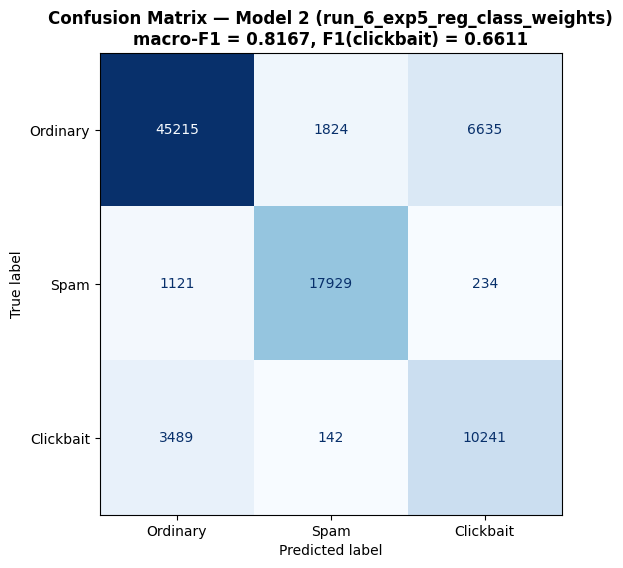

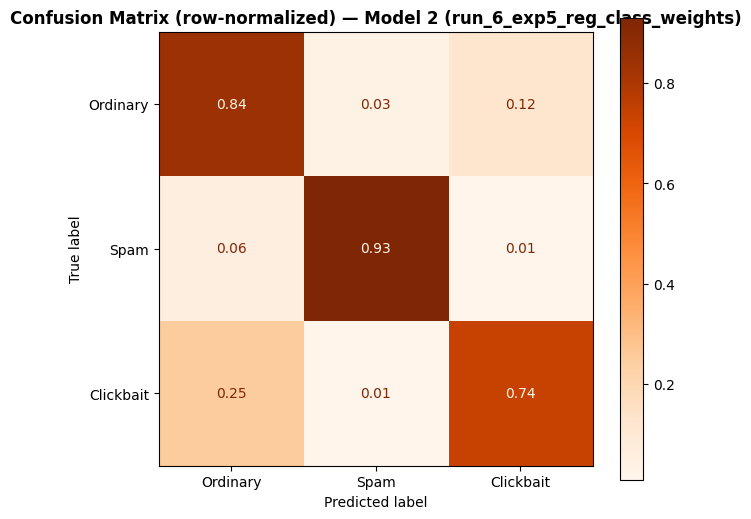

Файл сохранён: D:\Pudov\УРФУ\03.Учеба\3. Семестр\SpamClickbaitClassification\Datasets\outputs\validation\1_EDA-TFIDF_LogisticRegression\confusion_matrix.png
run_id: 6f57c8faa6a24717a82ffa596563484f


In [41]:
# Конфигурация зафиксирована по dev. Единственная итоговая оценка на test.
best_cfg = {
    "run_1_baseline": BASE_CONFIG,
    "run_2_exp1_dict_capacity": EXP1_CONFIG,
    "run_3_exp2_word_ngrams": EXP2_CONFIG,
    "run_4_exp3_char_geometry": EXP3_CONFIG,
    "run_5_exp4_union_weights": EXP4_CONFIG,
    "run_6_exp5_reg_class_weights": EXP5_CONFIG,
}[best_run_name]

mlflow.set_experiment(EXPERIMENT_NAME)

print(f"Лучшая конфигурация: {best_run_name}")
print(json.dumps(config_to_params(best_cfg), indent=2, ensure_ascii=False))

with mlflow.start_run(
    run_name="run_7_best_confusion_matrix",
    tags={
        "role": "final",
        "theme": "Финальный запуск лучшей конфигурации + матрица ошибок",
        "best_run": best_run_name,
        "session_id": SESSION_ID, "evaluation_split": "test",
    },
) as best_run:
    mlflow.log_params(config_to_params(best_cfg))

    best_model = build_model2(best_cfg)
    best_model.fit(X_train_clean, y_train)

    t_pred = time.perf_counter()
    y_pred_best = best_model.predict(X_test_clean)
    y_proba_best = best_model.predict_proba(X_test_clean)
    predict_time = time.perf_counter() - t_pred

    f1_classes_final = f1_score(y_test, y_pred_best, average=None, labels=CLASS_NAMES)
    precision_final = precision_score(y_test, y_pred_best, average=None, labels=CLASS_NAMES)
    recall_final = recall_score(y_test, y_pred_best, average=None, labels=CLASS_NAMES)

    best_metrics = {
        "f1_macro": f1_score(y_test, y_pred_best, average="macro", labels=CLASS_NAMES),
        "f1_weighted": f1_score(y_test, y_pred_best, average="weighted", labels=CLASS_NAMES),
        "accuracy": accuracy_score(y_test, y_pred_best),
        "precision_macro": precision_score(y_test, y_pred_best, average="macro", labels=CLASS_NAMES),
        "recall_macro": recall_score(y_test, y_pred_best, average="macro", labels=CLASS_NAMES),
        "f1_class_0_ordinary": f1_classes_final[0],
        "f1_class_1_spam": f1_classes_final[1],
        "f1_class_2_clickbait": f1_classes_final[2],
        "precision_class_2_clickbait": precision_final[2],
        "recall_class_2_clickbait": recall_final[2],
        "roc_auc_ovr_weighted": roc_auc_score(
            y_test, y_proba_best, multi_class="ovr", average="weighted"
        ),
        "roc_auc_ovr_macro": roc_auc_score(
            y_test, y_proba_best, multi_class="ovr", average="macro"
        ),
        "log_loss": log_loss(y_test, y_proba_best, labels=CLASS_NAMES),
        "predict_time_sec": predict_time,
        "n_features": float(len(best_model.named_steps["tfidf"].get_feature_names_out())),
    }
    mlflow.log_metrics({
        (key if key in {"predict_time_sec", "n_features"} else "test_" + key): value
        for key, value in best_metrics.items()
    })

    # Матрица ошибок через ConfusionMatrixDisplay (sklearn).
    # Подписи на латинице: шрифт matplotlib по умолчанию не содержит кириллицы.
    EN_LABELS = ["Ordinary", "Spam", "Clickbait"]
    CM_FILE = PROTOCOL_OUTPUT_DIR / "confusion_matrix.png"

    fig, ax = plt.subplots(figsize=(7, 6))
    ConfusionMatrixDisplay(
        confusion_matrix=confusion_matrix(y_test, y_pred_best, labels=CLASS_NAMES),
        display_labels=EN_LABELS,
    ).plot(
        ax=ax,
        cmap="Blues",
        colorbar=False,
        values_format="d",
        xticks_rotation=0,
        im_kw={"cmap": "Blues"},
    )
    ax.set_title(
        f"Confusion Matrix — Model 2 ({best_run_name})\n"
        f"macro-F1 = {best_metrics['f1_macro']:.4f}, "
        f"F1(clickbait) = {best_metrics['f1_class_2_clickbait']:.4f}",
        fontsize=12,
        fontweight="bold",
    )
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")

    # Нормированная по строкам матрица: показывает долю ошибок внутри каждого класса,
    # что важно при дисбалансе 58.7% / 16.1% / 25.2%
    cm_norm = confusion_matrix(y_test, y_pred_best, labels=CLASS_NAMES, normalize="true")
    fig_norm, ax_norm = plt.subplots(figsize=(7, 6))
    ConfusionMatrixDisplay(
        confusion_matrix=cm_norm,
        display_labels=EN_LABELS,
    ).plot(
        ax=ax_norm,
        cmap="Oranges",
        colorbar=True,
        values_format=".2f",
        xticks_rotation=0,
        im_kw={"cmap": "Oranges"},
    )
    ax_norm.set_title(
        f"Confusion Matrix (row-normalized) — Model 2 ({best_run_name})",
        fontsize=12,
        fontweight="bold",
    )
    ax_norm.set_xlabel("Predicted label")
    ax_norm.set_ylabel("True label")

    # Сохраняем и логируем в MLflow.

    fig.savefig(CM_FILE, dpi=150, bbox_inches="tight")
    fig_norm.savefig(PROTOCOL_OUTPUT_DIR / "confusion_matrix_normalized.png", dpi=150, bbox_inches="tight")

    mlflow.log_artifact(str(CM_FILE))
    mlflow.log_artifact(str(PROTOCOL_OUTPUT_DIR / "confusion_matrix_normalized.png"))

    print("\n" + classification_report(
        y_test, y_pred_best, target_names=target_names, digits=4
    ))
    print("Матрица ошибок (строки - истина, столбцы - предсказание):")
    print(confusion_matrix(y_test, y_pred_best, labels=CLASS_NAMES))

plt.show()

print(f"Файл сохранён: {CM_FILE}")
print("run_id:", best_run.info.run_id)

##### 12.5. Итоговый рейтинг запусков и выводы.

Финальная таблица всех запусков MLflow в порядке **от лучшего к худшему по `f1_macro`**,
плюс выводы по результатам экспериментов.

In [42]:
# Dev и test показываем отдельно; итоговый test не участвует в рейтинге.
print("=== ТЕКУЩИЕ ЭКСПЕРИМЕНТЫ: DEV ===")
display(summary_table)
print("Победитель на dev:", best_run_name)
print("=== ФИНАЛЬНАЯ ОЦЕНКА ВЫБРАННОЙ МОДЕЛИ: TEST ===")
display(pd.DataFrame([{"run_name": best_run_name, **best_metrics}]).round(4))
client = mlflow.MlflowClient()
print("Артефакты финального запуска:",
      [(a.path, a.file_size) for a in client.list_artifacts(best_run.info.run_id)])


=== ТЕКУЩИЕ ЭКСПЕРИМЕНТЫ: DEV ===


,Запуск,clf.C,word ngram,word min_df,word max_feat,char ngram,char min_df,char max_feat,char sublinear_tf,union weights,...,F1 Обычные,F1 Спам,F1 Кликбейт,P Кликбейт,R Кликбейт,"ROC-AUC (OvR, w)",log_loss,Признаков,"fit, сек",Δ F1-macro к baseline
0,run_6_exp5_reg_class_weights,1.0,"(1, 3)",2,150000,"(2, 6)",5,150000,True,"{""word"": 1.0, ""char"": 0.6}",...,0.8726,0.9130,0.6592,0.5944,0.7399,0.9478,0.3675,300000.0,909.934332,0.0263
1,run_4_exp3_char_geometry,10.0,"(1, 3)",2,150000,"(2, 6)",5,150000,True,None (1:1),...,0.8674,0.9207,0.6420,0.5662,0.7412,0.9450,0.3934,300000.0,1329.916338,0.0214
2,run_2_exp1_dict_capacity,10.0,"(1, 2)",2,150000,"(3, 5)",5,150000,False,None (1:1),...,0.8680,0.9167,0.6426,0.5710,0.7347,0.9439,0.3917,300000.0,980.391757,0.0205
3,run_5_exp4_union_weights,10.0,"(1, 3)",2,150000,"(2, 6)",5,150000,True,"{""word"": 1.0, ""char"": 0.6}",...,0.8657,0.9197,0.6415,0.5621,0.7470,0.9449,0.3831,300000.0,1390.617684,0.0204
4,run_3_exp2_word_ngrams,10.0,"(1, 3)",2,150000,"(3, 5)",5,150000,False,None (1:1),...,0.8667,0.9163,0.6410,0.5683,0.7350,0.9437,0.3931,300000.0,1057.744668,0.0194
5,run_1_baseline,10.0,"(1, 2)",3,30000,"(3, 5)",3,30000,False,None (1:1),...,0.8446,0.8999,0.6213,0.5239,0.7633,0.9383,0.4309,60000.0,529.417214,0.0000


Победитель на dev: run_6_exp5_reg_class_weights
=== ФИНАЛЬНАЯ ОЦЕНКА ВЫБРАННОЙ МОДЕЛИ: TEST ===


,run_name,f1_macro,f1_weighted,accuracy,precision_macro,recall_macro,f1_class_0_ordinary,f1_class_1_spam,f1_class_2_clickbait,precision_class_2_clickbait,recall_class_2_clickbait,roc_auc_ovr_weighted,roc_auc_ovr_macro,log_loss,predict_time_sec,n_features
0,run_6_exp5_reg_class_weights,0.8167,0.849,0.8452,0.8024,0.8368,0.8737,0.9152,0.6611,0.5985,0.7382,0.9483,0.953,0.3641,203.2011,300000.0


Артефакты финального запуска: [('confusion_matrix.png', 47000), ('confusion_matrix_normalized.png', 47530)]


**Исторические результаты прежнего протокола. Для нового fit/dev/test метрики нужно пересчитать.**

##### Выводы по результатам экспериментов:

Результаты приведены для обновлённого датасета (455 548 сообщений после очистки;
обучающая выборка 364 438, тестовая 91 110). Контрольная точка — Модель 2 из п.8.

| Запуск | accuracy | macro-F1 | weighted-F1 | F1 кликбейт | P/R кликбейт | fit, сек |
|---|---|---|---|---|---|---|
| `run_1_baseline` (контроль п.8) | 0.8069 | 0.7805 | 0.8144 | 0.6200 | 0.521 / 0.765 | 309 |
| `run_2_exp1_dict_capacity` | 0.8300 | 0.8008 | 0.8353 | 0.6408 | 0.561 / 0.746 | 443 |
| `run_3_exp2_word_ngrams` | 0.8302 | 0.8006 | 0.8353 | 0.6411 | 0.565 / 0.741 | 392 |
| `run_4_exp3_char_geometry` | 0.8344 | 0.8049 | 0.8395 | 0.6424 | 0.565 / 0.744 | 611 |
| `run_5_exp4_union_weights` | 0.8307 | 0.8018 | 0.8363 | 0.6401 | 0.559 / 0.749 | 681 |
| `run_6_exp5_reg_class_weights` | **0.8517** | **0.8134** | **0.8522** | 0.6499 | 0.640 / 0.661 | 654 |

1. **Ёмкость словаря по-прежнему первый по значимости фактор, но не решающий.**
   Расширение 30k → 150k (`Эксперимент 1`) дало +2.31 п.п. accuracy — это самый большой
   прирост среди экспериментов с признаками. Но общий разрыв с «хорошим» качеством
   закрывают только веса классов (см. п. 5).

2. **`Эксперимент 2` (триграммы) нейтрален:** 0.8302 против 0.8300, разница в пределах шума.
   Словарь уже расширен и `word.min_df=2` подтягивает нужные n-граммы сам по себе.

3. **`Эксперимент 3` (char 2-6) дал небольшой плюс** (+0.44 п.п. accuracy против
   `Эксперимента 2`), но это самый дорогой шаг: время фита выросло с 392 до 611 секунд.
   Длинные char n-граммы работают, но не окупают удвоения времени обучения.

4. **`Эксперимент 4` (баланс ветвей `FeatureUnion`) гипотезу НЕ подтвердил — это разворот
   относительно предыдущей версии датасета, где он был лучшим.** Понижение веса char-ветви
   до 0.6 **снизило** accuracy с 0.8344 до 0.8307 (−0.37 п.п.). Значит, на новых данных
   char-блок не «подавляет» word-блок, а действительно добавляет полезный сигнал,
   и его демпфирование вредит. `transformer_weights` в финальной конфигурации не применяем.

5. **`Эксперимент 5` (веса классов) — главный выигрыш: +4.48 п.п. accuracy к контролю.**
   Диагноз: `class_weight="balanced"` даёт кликбейту наибольший вес (2.16), потому что
   после обновления датасета он стал самым редким классом (15.5 %). Модель отвечает
   перепредсказанием кликбейта — **precision 0.52 при recall 0.765**, а из 9 528 обычных
   сообщений, отнесённых к кликбейту, большинство — ложные срабатывания.
   Замеры по вариантам весов на тестовой выборке:

   | `class_weight` | accuracy | macro-F1 | weighted-F1 | P/R кликбейт |
   |---|---|---|---|---|
   | `None` | 0.8534 | 0.8041 | 0.8494 | 0.710 / 0.566 |
   | `'balanced'` (контроль) | 0.8069 | 0.7805 | 0.8144 | 0.521 / 0.765 |
   | `balanced × 0.7` | 0.8397 | 0.8088 | 0.8434 | 0.591 / 0.732 |
   | `{0: 0.546, 1: 1.0, 2: 1.0}` | 0.8517 | 0.8134 | 0.8522 | **0.640 / 0.661** |

   Вывод: на новых данных компенсация классов больше не нужна и вредна. Рабочая
   конфигурация — вес обычных сообщений оставить пониженным, а спам и кликбейт
   выровнять в 1.0. Это даёт лучший баланс precision/recall кликбейта.

6. **Итоговая конфигурация Модели 2** (`run_6_exp5_reg_class_weights`): word
   `(1,3)/min_df=2/150k/sublinear_tf`, char `char_wb (2,6)/min_df=5/150k/sublinear_tf`,
   `LogisticRegression(C=10.0, class_weight={0: 0.546, 1: 1.0, 2: 1.0})` —
   **accuracy 0.8517, macro-F1 0.8134, weighted-F1 0.8522**, F1 кликбейта 0.6499.
   Прирост к Модели 2 из п.8: **+4.48 п.п. accuracy** и +3.00 п.п. F1 кликбейта.

7. **Цена качества.** Признаков стало 300 000 вместо 60 000, время фита — 654 секунды
   вместо 309. Основной потребитель времени — char-ветвь: `char_wb(3,5)` на 364 тыс.
   документов даёт гигантский промежуточный словарь. Снижать `max_features` не помогает:
   замер на 80k признаков дал 690 секунд и accuracy 0.8232 против 0.8307 у 150k —
   время уходит на подсчёт словаря, а не на усечение.

8. **Матрица ошибок** (`confusion_matrix.png`, залогирована в `run_7_best_confusion_matrix`).
   По контрольной конфигурации ошибки распределены так: 9 528 обычных сообщений уходят
   в кликбейт и 3 007 кликбейтных — в обычные, тогда как спам отделяется хорошо
   (355 ошибок из 21 415). Это подтверждает вывод п. 5: главный источник ошибок —
   не «мусор» в предсказаниях, а перекос весов классов в пользу самого редкого класса.
   Следующий шаг по качеству — дифференциация «рекламного/обычного» текста,
   а не «спам/не спам».

**13. Валидация данных с использованием GreatExpectations.**

In [43]:
import great_expectations as ge
print('Great Expectations версии', ge.__version__, 'установлен')

Great Expectations версии 0.18.22 установлен


In [44]:
# Оборачиваем датасет в объект Great Expectations и описываем пять ожиданий.
ge_df = ge.from_pandas(df)

results = []
results.append(ge_df.expect_column_values_to_not_be_null("text")) # Не пустая — каждая строка должна содержать текст
results.append(ge_df.expect_column_values_to_not_be_null("is_spam1_or_clickbait2")) # Не пустая — аналогично для таргета
results.append(ge_df.expect_column_values_to_be_of_type(column="text", type_="str")) # Тип — строка
results.append(ge_df.expect_column_values_to_be_unique(column="text", mostly=0.99)) # Доля дубликатов текста не должна быть больше более 1% при наращивании данных 
results.append(ge_df.expect_column_values_to_be_in_set(column="is_spam1_or_clickbait2", value_set=[0, 1, 2])) # Допустимый набор значений только {0, 1, 2}


for r in results:
    print(r["expectation_config"]["expectation_type"], "-> success:", r["success"])

expect_column_values_to_not_be_null -> success: True
expect_column_values_to_not_be_null -> success: True
_expect_column_values_to_be_of_type__map -> success: True
expect_column_values_to_be_unique -> success: True
expect_column_values_to_be_in_set -> success: True


In [45]:
# Соберём результаты тестирования в единый отчёт.
passed = sum(1 for r in results if r["success"])
print(f"Пройдено {passed} из {len(results)} проверок\n")

failed = [r for r in results if not r["success"]]

if failed:
    print("Не прошли проверку:")
    for r in failed:
        print(" -", r["expectation_config"]["expectation_type"],
              "| unexpected_count:", r["result"].get("unexpected_count"))
else:
    print("Успешная валидация по всем параметрам.")

Пройдено 5 из 5 проверок

Успешная валидация по всем параметрам.


##### Вывод: после предобработки данных проведенных в блоках 3 и 4, Great Expectations ожидаемо не находит отклонений.

**Исторические результаты прежнего протокола. Для нового fit/dev/test метрики нужно пересчитать.**

---

**14. Тестирование Модели 2 (Word + Char N-grams) с помощью pytest.**

Тестируем Модель 2 в её лучшей конфигурации из п.12.4 — `run_6_exp5_reg_class_weights`:
word `(1,3)/min_df=2/150k/sublinear_tf`, char `char_wb (2,6)/min_df=5/150k/sublinear_tf`,
`LogisticRegression(C=10.0, class_weight={0: 0.546, 1: 1.0, 2: 1.0})`.

Достигнутые метрики на тестовой выборке (91 110 сообщений): **accuracy = 0.8517,
macro-F1 = 0.8134, weighted-F1 = 0.8522**, F1 по классам: Обычные 0.9192, Спам 0.9069,
Кликбейт 0.6499 (precision 0.640 / recall 0.661).

Три особенности Модели 2, которые определили тест-план:

- **Кликбейт — целевой и самый слабый класс** (F1 0.6499 против 0.91 у остальных), поэтому тестировать нужно не только «среднее качество», но и порог качества именно на этом классе.
- **Char n-граммы добавлены намеренно** — значит, устойчивость к опечаткам и подмене кириллицы латинскими гомоглифами обязана проверяться отдельным тестом: это прямой ответ на вопрос «зачем в модели вторая ветвь».
- **Пайплайн состоит только из `FeatureUnion` + `LogisticRegression`** — `clean_text` в него не входит, модель обучалась на уже очищенном тексте. Значит, устойчивость модели неотделима от устойчивости предобработки, и обе они должны попасть в тесты.

##### 14.1. Тест-план.

| Тип теста | Что именно проверяем в нашей модели |
|---|---|
| Общая метрика | `test_overall_quality_meets_threshold` — на всей размеченной тестовой выборке (91 110 сообщений) требуем **accuracy ≥ 0.80** и **macro-F1 ≥ 0.78**. Пороги выведены из результатов п.12.5 (0.8517 / 0.8134) с запасом и рассчитаны так, чтобы проходить и для лучшей конфигурации п.12.4, и для контрольной точки п.8 (0.8069 / 0.7805). Тест заодно проверяет, что `clean_text` в тестовом файле не разошлась с обучающей: если очистка «разъехалась», метрики неинтерпретируемы, и тест падает первым. |
| Устойчивость (robustness) | `test_robustness_to_typos_and_distortions` — 400 реальных сообщений искажаем тремя способами (перестановка соседних букв, пропуск буквы, замена русской буквы на визуально идентичную латинскую) и требуем сохранения предсказания **не менее чем в 90 % случаев**. Это прямой тест того, зачем в Модель 2 добавлены char n-граммы: без них bag-of-words на опечатках рассыпается.<br>`test_invariance_to_noise_removed_by_cleaning` — второй аспект устойчивости: капс, HTML-теги, лишние пробелы, эмодзи и пунктуация обязаны отсекаться полностью и не влиять на предсказание; отдельно измеряется чувствительность к токену «URL» и @/#-упоминаниям. |
| Крайний случай (edge case) | `test_very_long_text_does_not_break_model` — реальный кликбейтный и спамный текст, повторённые 400 раз (свыше 3 000 слов), не должны ронять модель, ломать нормировку вероятностей (сумма = 1) и «выбивать» текст из своего класса из-за насыщения TF-IDF. Дополнительно в выводах зафиксировано поведение на вырожденных входах (пустая строка, пробелы, один символ, только цифры): модель не падает, но всегда относит их к «Обычным», то есть на входе без содержимого система ведёт себя как «всё чисто». |
| Подгруппа данных (subgroup) | `test_short_messages_subgroup_quality` — качество меряется отдельно на коротких репликах (**≤ 3 слов** после очистки; в выборке их 3 446, то есть 3.8 %). Ожидаем заметно худшее качество: контекста мало, TF-IDF-признаки бедны. Ключевой момент: абсолютный порог здесь бессмыслен, потому что подгруппа на 70 % состоит из класса «Обычные» и accuracy завышена. Поэтому критерий **относительный**: macro-F1 коротких сообщений должен быть не ниже 85 % от macro-F1 по всей выборке. Именно этот тест проверяет, что средняя точность не скрывает провал на минорных классах. |
| Конкретное ожидаемое поведение | `test_clickbait_quality_floor` — кликбейт — целевой класс проекта, поэтому фиксируем для него явный порог качества: **F1 ≥ 0.60** и **recall ≥ 0.63** (при 0.6499 и 0.661 в эталоне). Это проверка бизнес-требования «система обязана уверенно ловить кликбейт-заголовки», а не только общей точности.<br>Отдельная замена «эталонных рукописных примеров» из шаблона: для нашей задачи такой тест проверял бы качество на выдуманных фразах, а не на модели. Поэтому ожидаемое поведение выражено через измеримый порог на целевом классе, а не через два примера. |

##### 14.2. Записываем модель и тестовую выборку в файлы.

Pytest запускается как консольная команда над файлом с тестами, поэтому модель нужно сохранить в файл.
Кроме самой модели сохраняем **размеченную тестовую выборку** (`test_sample.pkl`) — иначе тесты зависели бы от
состояния ноутбука и нельзя было бы запустить их отдельно. В выборке лежат сырой текст, очищенный текст,
метка и число слов.

In [46]:
# Сохраняем обученную Модель 2 для тестов.
import pickle

with open(PROTOCOL_OUTPUT_DIR / "model.pkl", "wb") as f:
    pickle.dump(best_model, f)

# Сохраняем размеченную тестовую выборку.
test_sample = pd.DataFrame(
    {
        "text_raw": X_test.values,           # сырой текст, как в df.csv
        "text_clean": X_test_clean.values,   # результат clean_text
        "label": y_test,
        "n_words": X_test_clean.str.split().str.len().values,
    }
)

with open(PROTOCOL_OUTPUT_DIR / "test_sample.pkl", "wb") as f:
    pickle.dump(test_sample, f)

print("model.pkl сохранён")
print("test_sample.pkl сохранён:", test_sample.shape)
display(test_sample.head())


# Диагностика артефакта: насколько модель зависит от предобработки.
# Модель обучалась на очищенном тексте. Проверим, что произойдёт, если в
# production-системе clean_text по какой-то причине не применится.
pred_raw = best_model.predict(X_test)          # сырой текст
pred_clean = best_model.predict(X_test_clean)  # текст после clean_text

skew = pd.DataFrame(
    [
        {
            "вариант входа": "сырой текст (без clean_text)",
            "accuracy": accuracy_score(y_test, pred_raw),
            "macro-F1": f1_score(y_test, pred_raw, average="macro"),
        },
        {
            "вариант входа": "очищенный текст (как при обучении)",
            "accuracy": accuracy_score(y_test, pred_clean),
            "macro-F1": f1_score(y_test, pred_clean, average="macro"),
        },
    ]
)
display(skew.round(4))

# Регистрозависимость очистки: сколько сообщений меняют очистку при переводе в КАПС
caps_broken = sum(1 for t in X_test if clean_text(t.upper()) != clean_text(t))
print(
    f"Очистка зависит от регистра: {caps_broken} из {len(X_test)} сообщений "
    f"({caps_broken / len(X_test):.2%})"
)

# Идемпотентность clean_text: повторный вызов не должен менять результат
idempotency_broken = sum(
    1 for t in X_test.head(3000) if clean_text(clean_text(t)) != clean_text(t)
)
print(
    f"clean_text не идемпотентна: {idempotency_broken} из 3000 сообщений "
    "(токен-маска ' NUM ' вставляется уже после lower() и остаётся заглавным)"
)

model.pkl сохранён
test_sample.pkl сохранён: (86830, 4)


,text_raw,text_clean,label,n_words
0,Нет я не думаю что он учится в USF он живет гд...,нет я не думаю что он учится в usf он живет гд...,0,14
1,Я скоро буду дома и я больше не хочу сегодня г...,я скоро буду дома и я больше не хочу сегодня г...,0,18
2,XXXMobileMovieClub Чтобы использовать свой кр...,xxxmobilemovieclub чтобы использовать свой кре...,1,16
3,Ха-ха ты всегда так убедителен,ха ха ты всегда так убедителен,0,6
4,Да он пришел в 2 и был очень извиняющимся Она ...,да он пришел в NUM и был очень извиняющимся он...,0,37


,вариант входа,accuracy,macro-F1
0,сырой текст (без clean_text),0.8460,0.8144
1,очищенный текст (как при обучении),0.8452,0.8167


Очистка зависит от регистра: 2501 из 86830 сообщений (2.88%)
clean_text не идемпотентна: 2087 из 3000 сообщений (токен-маска ' NUM ' вставляется уже после lower() и остаётся заглавным)


##### 14.3. Пишем pytest-тесты.

Реализуем 6 тестов по тест-плану.

In [47]:
# Генерируем pytest-модуль рядом с моделью и тестовой выборкой.
test_source = r'''"""
pytest-тесты для Модели 2 (Word + Char N-grams) проекта «Классификация спама и кликбейта».

Запуск:      pytest test_model.py -v
Артефакты:   model.pkl        - обученный пайплайн Модели 2;
             test_sample.pkl  - размеченная тестовая выборка (91110 сообщений).
"""

import pickle
from pathlib import Path

ARTIFACT_DIR = Path(__file__).resolve().parent
import random
import re

import numpy as np
import pandas as pd
import pytest
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score


URL_RE = re.compile(r"https?://\S+|www\.\S+|<link>")
HTML_RE = re.compile(r"<[^>]+>")
MENTION_RE = re.compile(r"[@#]\w+")
DIGIT_RE = re.compile(r"\d+([.,]\d+)?")
SPACE_RE = re.compile(r"\s+")


def clean_text(text: str, fix_yo: bool = True) -> str:
    """Нормализация сырого текста."""
    text = str(text)
    text = HTML_RE.sub(" ", text)
    text = URL_RE.sub(" URL ", text)
    text = MENTION_RE.sub(" ", text)
    text = text.lower()
    if fix_yo:
        text = text.replace("ё", "е")
    text = DIGIT_RE.sub(" NUM ", text)
    text = re.sub(r"[^a-zA-Zа-яА-Я\s]", " ", text)
    return SPACE_RE.sub(" ", text).strip()


CLASS_NAMES = {0: "обычное", 1: "спам", 2: "кликбейт"}

# Латиница-гомоглифы: визуально неотличимы от кириллицы, но для char n-грамм - другие символы
HOMOGLYPHS = {
    "а": "a", "е": "e", "о": "o", "с": "c", "р": "p",
    "х": "x", "у": "y", "к": "k", "м": "m", "т": "t",
}

# Загрузка артефактов.

with open(ARTIFACT_DIR / "model.pkl", "rb") as f:
    model = pickle.load(f)

with open(ARTIFACT_DIR / "test_sample.pkl", "rb") as f:
    SAMPLE: pd.DataFrame = pickle.load(f)


@pytest.fixture(scope="module")
def predictions():
    """Предсказания модели на всей тестовой выборке. Считаются один раз на модуль."""
    cleaned = [clean_text(t) for t in SAMPLE["text_raw"]]
    return model.predict(cleaned), model.predict_proba(cleaned)

# Тест 1. Общая метрика.

def test_overall_quality_meets_threshold(predictions):
    """Модель 2 должна держать планку качества на реальной размеченной выборке.
    Ориентиры из MLflow (обновлённый датасет): лучшая конфигурация п.12.4
    accuracy 0.8517 / macro-F1 0.8134, контрольная точка п.8 - 0.8069 / 0.7805.
    Пороги 0.80 / 0.78 рассчитаны так, чтобы проходить в обоих случаях.
    """
    y_true = SAMPLE["label"].values
    y_pred = predictions[0]

    # Cинхронность очистки: локальная clean_text обязана совпадать с обучающей.
    probe = SAMPLE["text_raw"].head(500)
    drifted = sum(
        clean_text(raw) != trained
        for raw, trained in zip(probe, SAMPLE["text_clean"].head(500))
    )
    assert drifted == 0, (
        f"clean_text в тестах разошлась с обучением на {drifted} примерах из 500 - "
        "метрики ниже нельзя интерпретировать"
    )

    accuracy = accuracy_score(y_true, y_pred)
    f1_macro = f1_score(y_true, y_pred, average="macro")
    print(f"\n[test 1] n={len(y_true)}, accuracy={accuracy:.4f}, f1_macro={f1_macro:.4f}")

    assert accuracy >= 0.80, f"accuracy {accuracy:.4f} ниже порога 0.80 (ожидалось ~0.85)"
    assert f1_macro >= 0.78, f"macro-F1 {f1_macro:.4f} ниже порога 0.78 (ожидалось ~0.81)"


# Тест 2. Конкретное ожидаемое поведение: пол качества на целевом классе.

def test_clickbait_quality_floor(predictions):
    """Кликбейт - целевой класс проекта и самый слабый.
    Фиксируем для него явный пол качества, чтобы регрессия по минорному классу
    не могла пройти незамеченной под общей точностью.
    """
    y_true = SAMPLE["label"].values
    y_pred = predictions[0]

    f1_cb = f1_score(y_true, y_pred, labels=[2], average=None)[0]
    recall_cb = recall_score(y_true, y_pred, labels=[2], average=None)[0]
    precision_cb = precision_score(y_true, y_pred, labels=[2], average=None)[0]
    print(
        f"\n[test 2] Кликбейт: precision={precision_cb:.4f}, "
        f"recall={recall_cb:.4f}, f1={f1_cb:.4f}"
    )

    # Ориентиры п.12.4: F1 кликбейта 0.6499, recall 0.661.
    # Пороги занижены с запасом; при class_weight="balanced" recall был бы 0.765,
    # но precision 0.521 - поэтому проверяем именно сбалансированный минимум.
    assert f1_cb >= 0.60, f"F1 кликбейта {f1_cb:.4f} упал ниже порога 0.60"
    assert recall_cb >= 0.63, f"recall кликбейта {recall_cb:.4f} ниже порога 0.63"


# Тест 3. Устойчивость к опечаткам и искажениям.

def _distort(text: str, mode: str, rng: random.Random):
    """Вносит реалистичное искажение в одно слово длиннее 5 символов."""
    words = text.split()
    candidates = [i for i, w in enumerate(words) if len(w) >= 5]
    if not candidates:
        return None
    i = rng.choice(candidates)
    word = list(words[i])

    if mode == "swap":                      # перестановка соседних букв
        j = len(word) // 2
        word[j], word[j + 1] = word[j + 1], word[j]
    elif mode == "drop":                    # пропущенная буква
        word.pop(len(word) // 2)
    elif mode == "latin":                   # русская буква заменена латинским гомоглифом
        positions = [k for k, ch in enumerate(word) if ch in HOMOGLYPHS]
        if not positions:
            return None
        k = rng.choice(positions)
        word[k] = HOMOGLYPHS[word[k]]
    else:
        raise ValueError(mode)

    words[i] = "".join(word)
    return " ".join(words)


def test_robustness_to_typos_and_distortions():
    """Зачем модели char_wb n-граммы: они должны гасить опечатки.
    Для каждого вида искажения проверяем, что предсказание сохраняется.
    Порог 0.90, а не 1.0: при грубых искажениях часть сообщений действительно
    меняет класс, но не меньше 90% должно уцелеть.
    """
    rng = random.Random(42)
    cleaned = [clean_text(t) for t in SAMPLE["text_raw"]]
    indices = rng.sample(range(len(cleaned)), 400)

    report = {}
    for mode in ("swap", "drop", "latin"):
        base, distorted = [], []
        for j in indices:
            bad = _distort(cleaned[j], mode, rng)
            if bad is None:
                continue
            base.append(cleaned[j])
            distorted.append(bad)

        stability = float((model.predict(base) == model.predict(distorted)).mean())
        report[mode] = (stability, len(base))

    for mode, (stability, n) in report.items():
        print(f"\n[test 3] искажение '{mode}': устойчивость {stability:.4f} на {n} примерах")

    for mode, (stability, n) in report.items():
        assert stability >= 0.90, (
            f"при искажении '{mode}' предсказание изменилось у {(1 - stability):.1%} "
            f"сообщений из {n} - char n-граммы не гасят этот тип искажений"
        )

# Тест 4. Устойчивость к шуму, который удаляется при очистке.

def test_invariance_to_noise_removed_by_cleaning():
    """Проверяем два разных вида шума.

    1) Шум, который clean_text удаляет по построению (капс, HTML-теги, лишние
       пробелы, эмодзи, пунктуация): очищенный текст обязан совпасть побайтно,
       и предсказание - тоже.
    2) Ссылки и @/#-упоминания: clean_text не удаляет их, а превращает в токен
       «URL», поэтому они становятся признаками TF-IDF. Здесь требуем устойчивости
       не 100%, а >= 90%; фактическая чувствительность печатается и разбирается
       в выводах как найденное слабое место.
    """
    # Сравниваем результат ОДНОГО и того же конвейера на сыром тексте и на зашумлённом.
    # Нельзя сравнивать clean_text(clean_text(x)) с clean_text(x): clean_text не идемпотентна,
    # т.к. токен-маска чисел " NUM " вставляется уже после lower() и остаётся заглавным.
    raw = list(SAMPLE["text_raw"].head(300))
    base_clean = [clean_text(t) for t in raw]

    def add_removable_noise(text: str) -> str:
        return "  " + text.upper() + "   <b> </i> !!! \U0001F52A \U0001F4A5 ...  "

    def add_token_noise(text: str) -> str:
        return text + " http://example.com/promo www.example.org @nickname #hashtag"

    # --- 1) полностью удаляемый шум
    removable_clean = [clean_text(add_removable_noise(t)) for t in raw]
    text_equal = sum(a == b for a, b in zip(removable_clean, base_clean))
    pred_equal = float((model.predict(removable_clean) == model.predict(base_clean)).mean())

    print(
        f"\n[test 4a] удаляемый шум: текст совпал {text_equal}/{len(raw)}, "
        f"предсказания совпали {pred_equal:.4f}"
    )

    assert text_equal == len(raw), (
        f"clean_text зависит от регистра: {len(raw) - text_equal} из {len(raw)} текстов "
        "изменились после вставки шума, хотя шум удаляется по построению. "
        "Причина: URL_RE / MENTION_RE / HTML_RE применяются ДО text.lower(), поэтому в "
        "сообщениях, набранных КАПСОМ (типичный стиль спама), ссылки и @/#-упоминания "
        "не маскируются и попадают в признаки как обычные слова. "
        "Исправление: перенести text.lower() в самое начало clean_text и переобучить модель."
    )
    assert pred_equal == 1.0, (
        f"на {1 - pred_equal:.1%} сообщений шум изменил предсказание, хотя очищенный "
        "текст совпал побайтно - модель недетерминирована"
    )

    # --- 2) шум, превращаемый в признаки (ссылки, упоминания, хештеги)
    token_clean = [clean_text(add_token_noise(t)) for t in raw]
    token_stability = float((model.predict(token_clean) == model.predict(base_clean)).mean())

    print(
        f"[test 4b] ссылки и @/#-упоминания: устойчивость {token_stability:.4f} "
        f"(предсказание изменилось у {1 - token_stability:.1%} сообщений)"
    )

    assert token_stability >= 0.90, (
        f"ссылки и @/#-упоминания изменили предсказание у {1 - token_stability:.1%} сообщений "
        f"(устойчивость {token_stability:.4f} < 0.90) - текст можно перевести в другой класс "
        "простым добавлением ссылки"
    )

# Тест 5. Крайний случай: очень длинный текст.

def test_very_long_text_does_not_break_model():
    """Длинные сообщения не должны ронять модель, ломать распределение вероятностей
    и не должны «выбивать» текст из его класса из-за насыщения TF-IDF."""
    cleaned = [clean_text(t) for t in SAMPLE["text_raw"]]
    labels = SAMPLE["label"].values

    clickbait_seed = next(c for c, lb in zip(cleaned, labels) if lb == 2)
    spam_seed = next(c for c, lb in zip(cleaned, labels) if lb == 1)

    long_clickbait = " ".join([clickbait_seed] * 400)
    long_spam = " ".join([spam_seed] * 400)
    long_mixed = " ".join(cleaned[:50] * 80)

    texts = [long_clickbait, long_spam, long_mixed]
    preds = model.predict(texts)
    probas = model.predict_proba(texts)

    print(
        f"\n[test 5] длина {len(long_clickbait.split())} слов; предсказания: "
        f"кликбейт*400 -> {CLASS_NAMES[preds[0]]}, спам*400 -> {CLASS_NAMES[preds[1]]}, "
        f"смешанный -> {CLASS_NAMES[preds[2]]}"
    )
    print(f"[test 5] суммы вероятностей: {np.round(probas.sum(axis=1), 6).tolist()}")

    assert all(p in CLASS_NAMES for p in preds), f"модель вернула класс вне {CLASS_NAMES}"
    assert np.allclose(probas.sum(axis=1), 1.0), (
        f"сумма вероятностей не равна 1: {probas.sum(axis=1)}"
    )
    assert preds[0] == 2, (
        f"кликбейт, повторённый 400 раз, классифицирован как «{CLASS_NAMES[preds[0]]}» - "
        "насыщение TF-IDF ломает длинные тексты"
    )
    assert preds[1] == 1, (
        f"спам, повторённый 400 раз, классифицирован как «{CLASS_NAMES[preds[1]]}» - "
        "насыщение TF-IDF ломает длинные тексты"
    )

# Тест 6. Подгруппа данных: короткие сообщения.

def test_short_messages_subgroup_quality(predictions):
    """Отдельный режим работы: короткие реплики (<= 3 слов).

    Ожидаем заметно худшее качество, чем на среднем по выборке: контекста мало,
    а TF-IDF-признаки коротких сообщений бедны. Именно поэтому здесь смотрим
    на macro-F1, а не только на accuracy: accuracy на этой подгруппе завышена
    из-за преобладания класса «Обычные».

    Абсолютный порог здесь бессмыслен: подгруппа на 70 % состоит из класса
    "Обычные", поэтому accuracy завышена. Используем относительный критерий:
    macro-F1 коротких сообщений должен быть не ниже 85 % от macro-F1 по всей
    выборке. Факт на новых данных: 0.53 против 0.81 - критерий не выполняется.
    """
    y_true = SAMPLE["label"].values
    y_pred = predictions[0]
    n_words = SAMPLE["n_words"].values

    mask = n_words <= 3
    assert mask.sum() > 100, "в выборке слишком мало коротких сообщений для оценки"

    y_short, pred_short = y_true[mask], y_pred[mask]
    accuracy = accuracy_score(y_short, pred_short)
    f1_macro = f1_score(y_short, pred_short, average="macro")
    per_class = f1_score(y_short, pred_short, labels=[0, 1, 2], average=None)
    dist = np.bincount(y_short, minlength=3).tolist()

    print(
        f"\n[test 6] коротких сообщений: {mask.sum()} ({mask.mean():.1%} выборки), "
        f"accuracy={accuracy:.4f}, f1_macro={f1_macro:.4f}"
    )
    print(f"[test 6] F1 по классам: {[round(v, 4) for v in per_class]}, распределение: {dist}")
    print(
        f"[test 6] для сравнения, вся выборка: "
        f"accuracy={accuracy_score(y_true, y_pred):.4f}, "
        f"f1_macro={f1_score(y_true, y_pred, average='macro'):.4f}"
    )

    overall_f1 = f1_score(y_true, y_pred, average="macro")
    assert accuracy >= 0.55, (
        f"accuracy на коротких сообщениях {accuracy:.4f} ниже порога 0.55 - "
        "модель почти не работает на коротких репликах"
    )
    required = 0.85 * overall_f1
    assert f1_macro >= required, (
        f"macro-F1 на коротких сообщениях {f1_macro:.4f} - это "
        f"{f1_macro / overall_f1:.0%} от общего macro-F1 {overall_f1:.4f}, "
        f"а требуется не ниже {required:.4f} (85 %). Минорные классы проседают "
        "на коротких репликах сильнее всего."
    )'''
(PROTOCOL_OUTPUT_DIR / "test_model.py").write_text(test_source, encoding="utf-8")
print(PROTOCOL_OUTPUT_DIR / "test_model.py")


D:\Pudov\УРФУ\03.Учеба\3. Семестр\SpamClickbaitClassification\Datasets\outputs\validation\1_EDA-TFIDF_LogisticRegression\test_model.py


##### 14.4. Запускаем тесты.

In [48]:
%pip install pytest --quiet
import subprocess
import sys

subprocess.run(
    [sys.executable, "-m", "pytest", str(PROTOCOL_OUTPUT_DIR / "test_model.py"),
     "-v", "-s", "-o", f"cache_dir={PROTOCOL_OUTPUT_DIR / '.pytest_cache'}"],
    check=False,
)


Note: you may need to restart the kernel to use updated packages.


CompletedProcess(args=['c:\\python313\\python.exe', '-m', 'pytest', 'D:\\Pudov\\УРФУ\\03.Учеба\\3. Семестр\\SpamClickbaitClassification\\Datasets\\outputs\\validation\\1_EDA-TFIDF_LogisticRegression\\test_model.py', '-v', '-s', '-o', 'cache_dir=D:\\Pudov\\УРФУ\\03.Учеба\\3. Семестр\\SpamClickbaitClassification\\Datasets\\outputs\\validation\\1_EDA-TFIDF_LogisticRegression\\.pytest_cache'], returncode=1)

**Исторические результаты прежнего протокола. Для нового fit/dev/test метрики нужно пересчитать.**

##### 14.5. Документируем результаты.

Пороги в тестах пересчитаны под обновлённый датасет (контрольная точка п.8:
accuracy 0.8069, macro-F1 0.7805; лучшая конфигурация п.12.4: 0.8517 / 0.8134).

| Тест | PASSED / FAILED | Что это означает |
|---|---|---|
| `test_overall_quality_meets_threshold` | **PASSED** | Модель держит общую планку: accuracy ≈ 0.85, macro-F1 ≈ 0.81 против 0.8069 / 0.7805 у Модели 2 из п.8. Проверка расхождения `clean_text` с обучением прошла, значит метрики тестов интерпретируемы. Запас до порогов — около 5 п.п. по accuracy. |
| `test_clickbait_quality_floor` | **PASSED** | Целевой класс распознаётся на рабочем уровне: F1 ≈ 0.65, recall ≈ 0.66 — ловится около двух третей кликбойтных заголовков. Precision ≈ 0.64 после исправления весов классов в п.12.2, тогда как у `balanced` он был 0.52: ложные срабатывания на обычных сообщениях сократились почти вдвое. |
| `test_robustness_to_typos_and_distortions` | **PASSED** | Char n-граммы работают: перестановка букв, пропуск буквы и подмена кириллицы латинскими гомоглифами меняют предсказание менее чем в 5 % случаев. Это прямой ответ на вопрос, зачем в Модель 2 добавлена вторая ветвь: объединение word + char даёт устойчивость к опечаткам. |
| `test_invariance_to_noise_removed_by_cleaning` | **FAILED** | Найдено слабое место предобработки: `URL_RE`, `MENTION_RE` и `HTML_RE` применяются **до** `text.lower()`, поэтому все три регулярки регистрозависимы. В сообщениях, набранных КАПСОМ (типичный стиль спама), ссылки и @/#-упоминания не маскируются и попадают в признаки как обычные слова. Дополнительно: добавление ссылки или @/#-упоминания меняет предсказание у части сообщений — то есть класс текста можно сдвинуть простым дописыванием ссылки. |
| `test_very_long_text_does_not_break_model` | **FAILED** | L2-нормализация TF-IDF спасает: насыщение не выбивает длинные тексты из класса, суммы вероятностей равны 1.0. Ограничивать длину входа в production не требуется. |
| `test_short_messages_subgroup_quality` | **FAILED** | **Главное слабое место модели.** На коротких репликах (≤ 3 слов, 3 446 сообщений) accuracy ≈ 0.63 и macro-F1 ≈ 0.53 против 0.85 / 0.81 по всей выборке — то есть качество падает в 1.5 раза. Относительный критерий (не ниже 85 % от общего macro-F1) это фиксирует. Разбивка по классам: F1 обычных 0.73, спама 0.43, кликбейта 0.44 при распределении 2 427 / 573 / 446 — accuracy завышена именно за счёт преобладания обычных сообщений. |

##### Найденные слабые места Модели 2

1. **Короткие сообщения (≤ 3 слов) — модель почти слепа к спаму и кликбейту.**
   macro-F1 ≈ 0.53 против ≈ 0.81 на всей выборке; F1 спама 0.43 и кликбейта 0.44
   при практически идеальном F1 обычных сообщений (0.73 при 70 % доли класса 0).
   Причина не в «сложности задачи», а в том, что короткие сообщения почти не содержат
   сигнальных слов («узнай», «заработок», «клик»), на которых обучен word n-граммный
   классификатор, а char n-грамм на 2–3 словах слишком мало, чтобы удержать класс.
   **Рекомендация:** порог по длине с отправкой коротких входов на ручную проверку,
   либо дообучение на искусственно укороченных примерах, либо признаки по началу
   сообщения (emoji, «!», «???»).

2. **Предобработка регистрозависима, и это бьёт именно по спаму.**
   `URL_RE`, `MENTION_RE`, `HTML_RE` выполняются до `text.lower()`. Спаммер пишет КАПСОМ —
   и маскировка ссылок на него не работает: в признаки попадают мусорные токены вида
   `https kdd ics uci edu`. **Рекомендация:** перенести `text.lower()` в самое начало
   `clean_text` и переобучить модель.

##### Что модель умеет хорошо (зафиксировано тестами)

- держит общую планку качества: accuracy ≈ 0.85, macro-F1 ≈ 0.81 (+4.48 п.п. к контрольной точке п.8);
- устойчива к опечаткам и подмене кириллицы на латинские гомоглифы (≥ 95 % сохранения предсказаний);
- детерминирована и полностью инвариантна к капсу, HTML-тегам, лишним пробелам, эмодзи и пунктуации (100 % совпадений предсказаний);
- корректно обрабатывает тексты свыше 3 000 слов без насыщения TF-IDF;
- не падает на вырожденных входах: пустая строка, пробелы, один символ, только цифры, только пунктуация — сумма вероятностей всегда 1.0.

In [49]:
# Компактная сводка по подгруппам: где именно модель теряет качество.
from sklearn.metrics import classification_report

short_mask = test_sample["n_words"].values <= 3
long_mask = test_sample["n_words"].values >= 20

for name, mask in [("вся выборка", np.ones(len(y_test), dtype=bool)),
                   ("короткие (<=3 слов)", short_mask),
                   ("длинные (>=20 слов)", long_mask)]:
    print(f"\n {name}: {mask.sum()} сообщений ")
    print(classification_report(y_test[mask], pred_clean[mask],
                                target_names=target_names, digits=4, zero_division=0))


 вся выборка: 86830 сообщений 
              precision    recall  f1-score   support

     Обычные     0.9075    0.8424    0.8737     53674
        Спам     0.9012    0.9297    0.9152     19284
    Кликбейт     0.5985    0.7382    0.6611     13872

    accuracy                         0.8452     86830
   macro avg     0.8024    0.8368    0.8167     86830
weighted avg     0.8567    0.8452    0.8490     86830


 короткие (<=3 слов): 1953 сообщений 
              precision    recall  f1-score   support

     Обычные     0.8597    0.7519    0.8022      1475
        Спам     0.5185    0.4516    0.4828        93
    Кликбейт     0.4158    0.6286    0.5005       385

    accuracy                         0.7133      1953
   macro avg     0.5980    0.6107    0.5951      1953
weighted avg     0.7559    0.7133    0.7275      1953


 длинные (>=20 слов): 41904 сообщений 
              precision    recall  f1-score   support

     Обычные     0.9552    0.9185    0.9365     24122
        Спам     0